# Red Neuronal Cuántica Híbrida para la Predicción de Estructura de Proteínas

**Marco Antonio Roca Rodríguez** · Máster Universitario en Computación Cuántica (UNIR)
Director: Mariano Caruso · Entrega: septiembre de 2025

Repositorio: <https://github.com/marrocrod/qnn-protein_structure-prediction>

---

## Qué hace este trabajo

Predice el mapa de distancias entre carbonos alfa a partir de la secuencia de aminoácidos,
combinando las representaciones del modelo de lenguaje proteico **ESM-2** con un **circuito
cuántico variacional MERA de 12 qubits**, y reconstruye después la estructura tridimensional.

El modelo se entrena sobre `training_30` de ProteinNet CASP11 y se evalúa sobre el conjunto
de validación oficial de CASP11, que no interviene en ninguna fase del entrenamiento.

## Cómo se evalúa

La evaluación reproduce el protocolo del experimento CASP, lo que permite situar el
resultado frente a las ediciones históricas de la competición. Los contactos se agrupan en
rangos **exclusivos** de separación de secuencia:

| Rango | Separación | Dificultad |
|---|---|---|
| Corto | 6 – 11 | baja: refleja estructura secundaria local |
| Medio | 12 – 23 | media |
| **Largo** | **≥ 24** | **alta: es el rango que publica CASP** |

## Cómo recorrer el notebook

Las partes **I a IV** construyen y entrenan el modelo. La parte **V** lo evalúa con el
protocolo CASP. La parte **VI** contrasta el circuito cuántico contra un equivalente clásico.
La parte **VII** genera las tablas comparativas y **no necesita que se ejecute nada más**:
funciona con los resultados ya medidos. La parte **VIII** exporta estructuras para PyMOL.


## Contenido

| Parte | Contenido | Requiere ejecución previa |
|---|---|---|
| I | Configuración e hiperparámetros | — |
| II | Datos: representaciones, carga y ensamblado | I |
| III | Circuito cuántico y modelo híbrido | II |
| IV | Entrenamiento | III |
| V | Evaluación con el protocolo CASP | IV |
| VI | Ablación: circuito cuántico frente a equivalente clásico | III |
| VII | **Comparación con CASP** | **ninguna** |
| VIII | Exportación y visualización | IV |


---

# Parte I — Configuración

Punto único de ajuste del experimento. Aquí viven la semilla global, el tamaño de los conjuntos, los hiperparámetros de entrenamiento y los interruptores que activan o desactivan cada componente del estudio de ablación.


### Bloque 1 · Entorno y dependencias

Carga las librerías, fija la semilla y selecciona el dispositivo de cálculo.


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random, os, copy, warnings, json
from collections import defaultdict

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.manifold import MDS
from sklearn.metrics import confusion_matrix, classification_report

import pennylane as qml
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


### Bloque 2 · Hiperparámetros

Tamaño de los conjuntos, arquitectura, optimización y regularización. Modificar esta celda y reejecutar basta para reproducir cualquiera de las configuraciones estudiadas.


In [6]:

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# ── Config de entrenamiento ─────────────────────────────────
# ── Conjunto de entrenamiento ───────────────────────────────────────────────
# ProteinNet thinnings are NESTED subsets: training_30 c training_50 c ... c
# training_100. A higher number adds sequence redundancy, not new folds, so
# exactly one is chosen. Sizes measured on this dataset:
#   training_30  22,344 proteínas   training_70  36,005
#   training_50  29,936             training_100 87,573
TRAINING_SET = "training_100"

MAX_PROTEINS_TRAIN  = 5000
MAX_PER_BIN         = 20000   # 5 bins × 3000 = 15000 pares train
BATCH_SIZE          = 64
N_EPOCHS            = 120
EARLY_STOP_PATIENCE = 10

# ── Hiperparámetros del modelo ──────────────────────────────
DROPOUT_RATE = 0.5     # SUBIDO: mas regularizacion contra overfitting
WEIGHT_DECAY = 1e-2    # SUBIDO 5x: penaliza pesos grandes (anti-overfitting)
LR_CLASSICAL = 1e-3
LR_QUANTUM   = 3e-3    # igualado al clásico. Con init cerca de la identidad y
                       # Higher than the classical LR: quantum gradients are much smaller.

# ── Continuar desde checkpoint? ─────────────────────────────
LOAD_CHECKPOINT = False
CHECKPOINT_PATH = "checkpoint_best.pt"

# ── Config fija ─────────────────────────────────────────────
MIN_SEQ_SEP       = 6
BINS              = np.array([0, 4, 8, 12, 16, np.inf])
N_BINS            = len(BINS) - 1
BIN_CENTERS       = np.array([2.0, 6.0, 10.0, 14.0, 20.0])
COORD_SCALE       = 100.0
CONTACT_THRESHOLD = 8.0
MIN_SEQ_SEP_EVAL  = 6
LAMBDA_DIST       = 1.0
LAMBDA_ANG        = 0.3

print("Config activa:")
print(f"  Dataset             : casp11/{TRAINING_SET}")
print(f"  Proteínas de entrenamiento : {MAX_PROTEINS_TRAIN}")
print(f"  Pares/bin           : {MAX_PER_BIN}  →  {N_BINS * MAX_PER_BIN} pares train")
print(f"  Epochs / patience   : {N_EPOCHS} / {EARLY_STOP_PATIENCE}")
print(f"  Dropout / wd        : {DROPOUT_RATE} / {WEIGHT_DECAY}")
print(f"  Cargar checkpoint   : {LOAD_CHECKPOINT}")


# ── Modo de ejecución ───────────────────────────────────────────────────────
# "smoke" runs the whole pipeline in a couple of minutes to verify that nothing
# breaks; "full" is the long run. ALWAYS do a smoke run first before leaving the
# machine unattended for hours.
RUN_MODE = "full"          # "smoke" | "full"

if RUN_MODE == "smoke":
    MAX_PROTEINS_TRAIN  = 60
    MAX_PER_BIN         = 400
    N_EPOCHS            = 3
    EARLY_STOP_PATIENCE = 2

print(f"\nModo de ejecución: {RUN_MODE.upper()}")
print(f"  Proteínas de entrenamiento : {MAX_PROTEINS_TRAIN:,}")
print(f"  Pares por bin              : {MAX_PER_BIN:,}  "
      f"(total {MAX_PER_BIN * 5:,} pares)")
print(f"  Épocas máximas / paciencia : {N_EPOCHS} / {EARLY_STOP_PATIENCE}")


Config activa:
  Dataset             : casp11/training_100
  Proteínas de entrenamiento : 5000
  Pares/bin           : 20000  →  100000 pares train
  Epochs / patience   : 120 / 10
  Dropout / wd        : 0.5 / 0.01
  Cargar checkpoint   : False

Modo de ejecución: FULL
  Proteínas de entrenamiento : 5,000
  Pares por bin              : 20,000  (total 100,000 pares)
  Épocas máximas / paciencia : 120 / 10


---

# Parte II — Datos

Del fichero de ProteinNet a los tensores de entrenamiento. Se extraen las representaciones del modelo de lenguaje, se calcula la geometría de referencia a partir de las coordenadas experimentales y se ensambla un conjunto equilibrado de pares de residuos.


### Bloque 3 · Representaciones del modelo de lenguaje

Convierte cada secuencia en embeddings por residuo, mapas de atención por par y la predicción de contactos que el propio ESM-2 produce. Esta última sirve de referencia independiente en la evaluación.


In [7]:
# ─── ESM features v2: embeddings + ATENCIONES DE PAR ─────────────────────────

import numpy as np
import torch
import esm

esm_model, esm_alphabet = esm.pretrained.esm2_t12_35M_UR50D()
esm_model = esm_model.to(device)
esm_model.eval()
batch_converter = esm_alphabet.get_batch_converter()

ESM_REPR_LAYER = 6     # ← CAMBIO: capa intermedia, no la última (12).
                       # Intermediate layers encode structure better than the final ones.
ESM_EMB_DIM    = 480
N_ESM_LAYERS   = esm_model.num_layers          # 12
N_ESM_HEADS    = esm_model.layers[0].self_attn.num_heads  # 20
N_ATTN_FEATS   = N_ESM_LAYERS * N_ESM_HEADS    # 240 features de atención/par


@torch.no_grad()
def get_esm_features(sequence: str, mask: np.ndarray = None):
    """
    Devuelve, ya con la máscara estructural aplicada en AMBOS ejes:
      emb      : (Lm, 480)          embeddings por residuo (capa ESM_REPR_LAYER)
      attn     : (Lm, Lm, 240) f16  atención por par, simetrizada (i→j y j→i
                                     promediadas). f16 para ahorrar memoria.
      contacts : (Lm, Lm)      f32  prob. de contacto de ESM (baseline sin train)
    Si mask es None, no se filtra (Lm = L).
    """
    data = [("protein", sequence)]
    _, _, tokens = batch_converter(data)
    tokens = tokens.to(device)

    results = esm_model(
        tokens,
        repr_layers=[ESM_REPR_LAYER],
        need_head_weights=True,     # ← activa results["attentions"]
        return_contacts=True,       # ← activa results["contacts"]
    )

    # Representaciones: (1, T, 480) con T = L+2 (BOS/EOS) → quitamos extremos
    emb = results["representations"][ESM_REPR_LAYER][0, 1:-1]          # (L, 480)

    # Atenciones: (1, capas, cabezas, T, T) → quitamos BOS/EOS en ambos ejes
    attn = results["attentions"][0, :, :, 1:-1, 1:-1]                  # (Lc, H, L, L)

    # Contactos: (1, L, L) ya sin BOS/EOS, simetrizado+APC por ESM
    contacts = results["contacts"][0]                                  # (L, L)

    # Máscara estructural en los DOS ejes residuo
    if mask is not None:
        m = torch.as_tensor(mask, dtype=torch.bool, device=emb.device)
        emb      = emb[m]                                              # (Lm, 480)
        attn     = attn[:, :, m][:, :, :, m]                           # (Lc, H, Lm, Lm)
        contacts = contacts[m][:, m]                                   # (Lm, Lm)

    # (Lc, H, Lm, Lm) → (Lm, Lm, Lc*H) y simetrizamos i↔j (atención NO es simétrica)
    attn = attn.permute(2, 3, 0, 1).reshape(attn.shape[2], attn.shape[3], -1)
    attn = 0.5 * (attn + attn.transpose(0, 1))                         # (Lm, Lm, 240)

    return (emb.cpu().numpy(),
            attn.cpu().numpy().astype(np.float16),
            contacts.cpu().numpy())


def pair_feature_vector(emb, attn, contacts, i, j, extras=None,
                        use_emb=True, use_attn=True, use_contact=True):
    """
    Construye el vector de par (i,j) a partir de la salida de get_esm_features.
    Bloques activables para poder ablacionar cuál aporta:
      - use_emb     : [emb_i ‖ emb_j]              (960)  ← lo que ya tenías
      - use_attn    : atención simetrizada (i,j)   (240)  ← LA GANANCIA nueva
      - use_contact : contacto ESM (i,j)           (1)
      - extras      : tus 4 valores previos        (4)
    """
    parts = []
    if use_emb:
        parts.append(emb[i]); parts.append(emb[j])          # 480 + 480
    if use_attn:
        parts.append(attn[i, j].astype(np.float32))         # 240
    if use_contact:
        parts.append(np.array([contacts[i, j]], np.float32))# 1
    if extras is not None:
        parts.append(np.asarray(extras, np.float32))        # 4
    return np.concatenate(parts)


# Memory-safe pattern: attention maps are (Lm^2, 240) and cannot be cached
# for the whole dataset, so features are grouped per protein — ESM runs once
# per protein and its attention is discarded before moving to the next one.

def build_pair_dataset(df, pairs_per_protein, seed=0,
                       use_emb=True, use_attn=True, use_contact=True):
    """
    df: filas con 'sequence', 'coords' (Lm,3) y (opcional) 'mask' ya aplicada.
    Devuelve X (n_pares, D) y y_dist (n_pares,) binneado con BINS.
    Recalcula ESM por proteína → attn nunca se acumula.
    """
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []

    for _, rec in df.iterrows():
        seq, coords = rec["sequence"], rec["coords"]
        # coords is already masked (Lm,3); the embedding is recomputed on the full
# sequence and realigned by masked index.
        mask = rec.get("mask", None)
        emb, attn, contacts = get_esm_features(seq, mask=mask)
        Lm = coords.shape[0]

        # Muestreo de pares (i<j) para esta proteína
        n = min(pairs_per_protein, Lm * (Lm - 1) // 2)
        ii = rng.integers(0, Lm, size=n * 2)
        jj = rng.integers(0, Lm, size=n * 2)
        ok = ii < jj
        ii, jj = ii[ok][:n], jj[ok][:n]

        for i, j in zip(ii, jj):
            d = np.linalg.norm(coords[i] - coords[j])       # distancia real Å
            b = np.digitize(d, BINS) - 1                    # bin ordinal
            extras = _pair_extras(i, j, Lm, d)              # tus 4 extras
            X_list.append(pair_feature_vector(
                emb, attn, contacts, i, j, extras,
                use_emb, use_attn, use_contact))
            y_list.append(b)
        # aquí attn/emb/contacts salen de scope → memoria liberada

    return np.stack(X_list), np.array(y_list, np.int64)


def _pair_extras(i, j, Lm, d):
    """Placeholder: pon aquí TUS 4 extras reales (los que ya usabas)."""
    sep = abs(i - j) / Lm                    # separación de secuencia normalizada
    return np.array([i / Lm, j / Lm, sep, 0.0], np.float32)


### Bloque 4 · Carga del conjunto de datos

Lee los ficheros de ProteinNet y devuelve secuencia, máscara de residuos resueltos y coordenadas experimentales de cada proteína.


In [8]:
# ─── BLOQUE 4: carga de ProteinNet ───────────────────────────────────────────

def load_proteinnet(file_path, max_records=2000, sample=False, seed=None):
    """sample=True draws a uniform random sample over the WHOLE file (reservoir
    sampling, one pass). Without it only the first N entries are read, which
    biases the set towards contiguous — and often highly similar — proteins."""
    rng = np.random.default_rng(RANDOM_SEED if seed is None else seed)
    seen = 0
    records, blocks, current_key = [], {}, None

    def offer(rec):
        nonlocal seen
        seen += 1
        if len(records) < max_records:
            records.append(rec)
        else:
            j = rng.integers(0, seen)
            if j < max_records:
                records[j] = rec

    def flush():
        nonlocal blocks
        if not blocks: return None
        mask = np.array([c == '+' for c in blocks.get("MASK", [""])[0]])
        L, seq = len(mask), blocks.get("PRIMARY", [""])[0]
        tv = []
        for row in blocks.get("TERTIARY", []):
            tv.extend(map(float, row.split()))
        tv = np.array(tv)
        if tv.size == 0 or tv.size % (3 * L) != 0:
            blocks.clear(); return None
        coords = tv.reshape(-1, 3, L)[0].T[mask]        # (Lm, 3), ya enmascarado
        rec = {"id": blocks.get("ID", ["?"])[0],
               "sequence": seq,                          # secuencia COMPLETA
               "mask": mask,                             # bool (L,) para alinear
               "length": int(mask.sum()),                # Lm
               "coords": coords}                         # (Lm, 3)
        blocks.clear()
        return rec

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line: continue
            if line.startswith("[") and line.endswith("]"):
                key = line[1:-1]
                if key == "ID" and blocks:
                    rec = flush()
                    if rec:
                        offer(rec)
                        if not sample and len(records) >= max_records: break
                current_key = key
                blocks[current_key] = []
            elif current_key:
                blocks[current_key].append(line)
    rec = flush()
    if rec and (sample or len(records) < max_records):
        offer(rec)
    if sample:
        print(f"  muestreo aleatorio: {len(records)} de {seen} proteínas del fichero")
    return pd.DataFrame(records)

print(f"Cargando dataset {TRAINING_SET}...")
df_train = load_proteinnet(f"../casp11/{TRAINING_SET}",
                           max_records=MAX_PROTEINS_TRAIN, sample=True)
print(f"Train: {len(df_train)} proteínas")



Cargando dataset training_100...
  muestreo aleatorio: 5000 de 87573 proteínas del fichero
Train: 5000 proteínas


### Bloque 5 · Geometría de referencia

Calcula distancias y ángulos reales entre pares de residuos, que constituyen las etiquetas de entrenamiento, y selecciona los pares admisibles.


In [9]:
# ─── BLOQUE 5: geometría de referencia y extracción de pares ────────────────

def pairwise_distances(coords):
    diff = coords[:, None, :] - coords[None, :, :]
    return np.linalg.norm(diff, axis=-1)

def _normalize(v, eps=1e-8):
    n = np.linalg.norm(v)
    return v / n if n >= eps else v * 0.0

def tangent_vector(coords, i):
    L = coords.shape[0]
    if L < 2: return np.array([1., 0., 0.], dtype=np.float32)
    if i == 0:       t = coords[1] - coords[0]
    elif i == L - 1: t = coords[L-1] - coords[L-2]
    else:            t = coords[i+1] - coords[i-1]
    return _normalize(t).astype(np.float32)

def local_curvature(coords, i):
    L = coords.shape[0]
    if i == 0 or i == L - 1: return 0.0
    return float(np.linalg.norm(
        _normalize(coords[i+1] - coords[i]) - _normalize(coords[i] - coords[i-1])
    ))

N_ANGLE_BINS = 12
ANGLE_BINS   = np.linspace(0.0, np.pi, N_ANGLE_BINS + 1)

def angle_bin(coords, i, j):
    ti  = tangent_vector(coords, i)
    uij = _normalize(coords[j] - coords[i]).astype(np.float32)
    c   = float(np.clip(np.dot(ti, uij), -1.0, 1.0))
    b   = int(np.digitize(np.arccos(c), ANGLE_BINS) - 1)
    return int(np.clip(b, 0, N_ANGLE_BINS - 1))


def pair_geometry(coords, min_seq_sep=MIN_SEQ_SEP):
    """
    PASADA 1: solo geometría, sin ESM. Devuelve arrays ligeros por proteína:
      i_idx, j_idx : índices (en espacio ENMASCARADO, 0..Lm-1) de cada par i<j
      y_dist       : bin de distancia (label)
      y_a, y_b     : bins de ángulo direccionales (labels)
    coords ya viene enmascarado y escalado (/COORD_SCALE) desde el bloque 6.
    """
    L = coords.shape[0]
    D = pairwise_distances(coords)
    i_idx, j_idx = np.triu_indices(L, k=min_seq_sep)
    d_vals  = D[i_idx, j_idx]
    y_dist  = np.clip(np.digitize(d_vals, BINS) - 1, 0, N_BINS - 1).astype(np.int64)
    y_a = np.array([angle_bin(coords, int(i), int(j))
                    for i, j in zip(i_idx, j_idx)], dtype=np.int64)
    y_b = np.array([angle_bin(coords, int(j), int(i))
                    for i, j in zip(i_idx, j_idx)], dtype=np.int64)
    return (i_idx.astype(np.int32), j_idx.astype(np.int32), y_dist, y_a, y_b)

print("Utilidades geométricas listas (PASADA 1 sin ESM, sin fuga)")


Utilidades geométricas listas (PASADA 1 sin ESM, sin fuga)


### Bloque 6 · Ensamblado del conjunto de entrenamiento

Equilibra los pares por bin de distancia y por rango de separación, ajusta el escalado de características y construye los cargadores de datos. La división entre entrenamiento y monitorización se hace por proteína completa, de modo que no hay fuga de información.


In [10]:
# ─── BLOQUE 6: ensamblado, balanceo y DataLoaders ───────────────────────────

USE_ATTN    = True     # atención por par (240D) — LA señal nueva
USE_CONTACT = False     # mapa de contacto de ESM (1D)

# ── Balanceo por rango de separación de secuencia ───────────────────────────
# The pair quota of each distance bin is split across separation strata, so
# long-range pairs are guaranteed representation. Measured on training_30,
# random sampling per bin already yields ~67% long-range pairs while this
# rebalancing drops them to 33%, so it is disabled.
BALANCE_BY_SEP = False
SEP_STRATA = [(MIN_SEQ_SEP, 12), (12, 24), (24, 10**9)]   # corto / medio / largo
SEP_NAMES  = ["corto 6-11", "medio 12-23", "largo >=24"]

D_EMB  = ESM_EMB_DIM                                    # 480
N_FEAT = 2 * D_EMB + 1                                  # base: emb± + seq_sep = 961
if USE_ATTN:    N_FEAT += N_ATTN_FEATS                  # +240
if USE_CONTACT: N_FEAT += 1                             # +1
# → 1202 con todo activo; 961 con ambos flags en False (tu input original)

_rng = np.random.default_rng(RANDOM_SEED)


def _collect_geometry(df, indices, min_seq_sep):
    """PASADA 1: acumula pares de todas las proteínas como enteros ligeros."""
    P, I, J, YD, YA, YB = [], [], [], [], [], []
    for idx in indices:
        coords = df.iloc[idx]["coords"] / COORD_SCALE
        i_idx, j_idx, yd, ya, yb = pair_geometry(coords, min_seq_sep)
        n = len(i_idx)
        P.append(np.full(n, idx, np.int32))
        I.append(i_idx); J.append(j_idx); YD.append(yd); YA.append(ya); YB.append(yb)
    return (np.concatenate(P), np.concatenate(I), np.concatenate(J),
            np.concatenate(YD), np.concatenate(YA), np.concatenate(YB))


def _sep_stratum_ids(i, j):
    """Map each pair to a sequence-separation stratum index (-1 if outside)."""
    sep = (j.astype(np.int64) - i.astype(np.int64))
    ids = np.full(len(sep), -1, np.int8)
    for s, (lo, hi) in enumerate(SEP_STRATA):
        ids[(sep >= lo) & (sep < hi)] = s
    return ids


def _sep_report(title, i, j, yd):
    """Print the (separation stratum x distance bin) contingency table."""
    strata = _sep_stratum_ids(i, j)
    print(f"  {title}")
    header = f"    {'estrato':<14}" + "".join(f"{'bin'+str(b):>9}" for b in range(N_BINS)) + f"{'total':>10}"
    print(header)
    for s, name in enumerate(SEP_NAMES):
        row = [int(((strata == s) & (yd == b)).sum()) for b in range(N_BINS)]
        print(f"    {name:<14}" + "".join(f"{v:>9,}" for v in row) + f"{sum(row):>10,}")
    tot_long = int((strata == len(SEP_STRATA) - 1).sum())
    print(f"    -> pares de largo alcance: {tot_long:,} "
          f"({100.0 * tot_long / max(1, len(strata)):.1f}% del total)")


def _balance(prot, i, j, yd, ya, yb, max_per_bin):
    """Balance the pair pool.

    With BALANCE_BY_SEP the quota of each distance bin is split evenly across
    the sequence-separation strata, so long-range pairs are guaranteed
    representation. Unused quota (a stratum with too few pairs) is redistributed
    to the remaining pairs of the same bin, keeping the dataset size unchanged.
    """
    if not BALANCE_BY_SEP:
        keep = []
        for b in range(N_BINS):
            idxs = np.where(yd == b)[0]
            if len(idxs) == 0: continue
            if len(idxs) > max_per_bin:
                idxs = _rng.choice(idxs, size=max_per_bin, replace=False)
            keep.append(idxs)
        keep = np.concatenate(keep)
        return prot[keep], i[keep], j[keep], yd[keep], ya[keep], yb[keep]

    strata = _sep_stratum_ids(i, j)
    n_str  = len(SEP_STRATA)
    quota  = max_per_bin // n_str
    keep   = []
    for b in range(N_BINS):
        bin_idx = np.where(yd == b)[0]
        if len(bin_idx) == 0: continue
        chosen, deficit = [], 0
        for s in range(n_str):
            pool = bin_idx[strata[bin_idx] == s]
            take = min(quota, len(pool))
            if take > 0:
                chosen.append(_rng.choice(pool, size=take, replace=False))
            deficit += quota - take
        # Redistribute the unused quota among the remaining pairs of this bin
        if deficit > 0:
            already = np.concatenate(chosen) if chosen else np.array([], np.int64)
            rest = np.setdiff1d(bin_idx, already)
            if len(rest) > 0:
                chosen.append(_rng.choice(rest, size=min(deficit, len(rest)),
                                          replace=False))
        if chosen:
            keep.append(np.concatenate(chosen))
    keep = np.concatenate(keep)
    return prot[keep], i[keep], j[keep], yd[keep], ya[keep], yb[keep]


def _featurize(df, prot, i, j, yd, ya, yb):
    """PASADA 2: agrupa por proteína, ESM una vez por proteína, materializa X.
    La atención (Lm,Lm,240) es efímera: se libera al pasar de proteína."""
    order = np.argsort(prot, kind="stable")             # agrupa por proteína
    prot, i, j = prot[order], i[order], j[order]
    yd, ya, yb = yd[order], ya[order], yb[order]

    X = np.empty((len(prot), N_FEAT), np.float32)
    for p in np.unique(prot):
        seq  = df.iloc[p]["sequence"]; mask = df.iloc[p]["mask"]
        emb, attn, contacts = get_esm_features(seq, mask)   # ESM 1x/proteína
        Lm = emb.shape[0]
        sel = np.where(prot == p)[0]                        # contiguo tras el sort
        for k in sel:
            ii, jj = int(i[k]), int(j[k])
            parts = [emb[ii] + emb[jj],                     # 480 (simétrico)
                     np.abs(emb[ii] - emb[jj]),             # 480
                     np.array([(jj - ii) / Lm], np.float32)]# 1  seq_sep/Lm
            if USE_ATTN:
                parts.append(attn[ii, jj].astype(np.float32))     # 240
            if USE_CONTACT:
                parts.append(np.array([contacts[ii, jj]], np.float32))  # 1
            X[k] = np.concatenate(parts)
        # emb/attn/contacts salen de scope → RAM liberada
    return X, yd, ya, yb


def build_split(df, indices, max_per_bin, report=False):
    prot, i, j, yd, ya, yb = _collect_geometry(df, indices, MIN_SEQ_SEP)
    if report:
        print("── Diagnóstico de separación de secuencia ──────────────────")
        _sep_report("ANTES del balanceo (todos los pares disponibles):", i, j, yd)
    prot, i, j, yd, ya, yb = _balance(prot, i, j, yd, ya, yb, max_per_bin)
    if report:
        _sep_report(f"DESPUÉS del balanceo (BALANCE_BY_SEP={BALANCE_BY_SEP}):", i, j, yd)
        print()
    return _featurize(df, prot, i, j, yd, ya, yb)          # X, yd, ya, yb


# ── Split por proteína completa: sin solapamiento de pares entre subconjuntos ─
n_proteins = len(df_train)
train_idx, val_idx = train_test_split(
    list(range(n_proteins)), test_size=0.2, random_state=RANDOM_SEED
)

print("Construyendo train (PASADA 1 geometría → balanceo → PASADA 2 ESM)...")
X_train_raw, ydist_train, ya_train, yb_train = build_split(df_train, train_idx, MAX_PER_BIN, report=True)
print("Construyendo val...")
X_val_raw,   ydist_val,   ya_val,   yb_val   = build_split(df_train, val_idx,   MAX_PER_BIN)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled   = scaler.transform(X_val_raw)

X_train_t     = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t       = torch.tensor(X_val_scaled,   dtype=torch.float32)
ydist_train_t = torch.tensor(ydist_train, dtype=torch.long)
ydist_val_t   = torch.tensor(ydist_val,   dtype=torch.long)
ya_train_t    = torch.tensor(ya_train, dtype=torch.long)
ya_val_t      = torch.tensor(ya_val,   dtype=torch.long)
yb_train_t    = torch.tensor(yb_train, dtype=torch.long)
yb_val_t      = torch.tensor(yb_val,   dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(X_train_t, ydist_train_t, ya_train_t, yb_train_t),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(
    TensorDataset(X_val_t, ydist_val_t, ya_val_t, yb_val_t),
    batch_size=BATCH_SIZE, shuffle=False)

feat_desc = (f"{2*D_EMB}(emb±) + 1(seq_sep)"
             + (f" + {N_ATTN_FEATS}(attn)" if USE_ATTN else "")
             + (" + 1(contact)" if USE_CONTACT else ""))
print(f"Input dim   : {X_train_t.shape[1]}D  =  {feat_desc}")
print(f"  (attn={USE_ATTN}, contact={USE_CONTACT}; con ambos False = 961D original)")
print(f"Train pares : {len(X_train_t)}")
print(f"Val pares   : {len(X_val_t)}")
print(f"Bins train  : {dict(zip(*np.unique(ydist_train, return_counts=True)))}")


Construyendo train (PASADA 1 geometría → balanceo → PASADA 2 ESM)...
── Diagnóstico de separación de secuencia ──────────────────
  ANTES del balanceo (todos los pares disponibles):
    estrato            bin0     bin1     bin2     bin3     bin4     total
    corto 6-11      713,3642,612,2391,241,078  210,750  191,260 4,968,691
    medio 12-23     351,2491,833,7492,898,2172,233,6152,189,898 9,506,728
    largo >=24      688,1763,819,7609,033,61713,837,70394,285,868121,665,124
    -> pares de largo alcance: 121,665,124 (89.4% del total)
  DESPUÉS del balanceo (BALANCE_BY_SEP=False):
    estrato            bin0     bin1     bin2     bin3     bin4     total
    corto 6-11        8,204    6,357    1,918      264       39    16,782
    medio 12-23       3,946    4,429    4,483    2,887      450    16,195
    largo >=24        7,850    9,214   13,599   16,849   19,511    67,023
    -> pares de largo alcance: 67,023 (67.0% del total)

Construyendo val...
Input dim   : 1201D  =  960(emb±) + 1(

---

# Parte III — Modelo

Arquitectura híbrida: un embudo clásico reduce el vector de características a los ángulos que alimentan el circuito cuántico, cuyas mediciones vuelven a la parte clásica para producir las predicciones.


### Bloque 7 · Circuito cuántico MERA

Ansatz de renormalización multiescala sobre 12 qubits, con puertas de *disentangling* entre niveles y medición extendida del estado. Es el componente que distingue este trabajo de una red puramente clásica.


In [11]:
# ─── BLOQUE 7: circuito cuántico MERA (12 qubits) ───────────────────────────

import time
import torch
import torch.nn as nn

n_qubits = 12
CDTYPE   = torch.complex64

# ── Schedule MERA: (wires_reupload, disentanglers, isometrías) por nivel ──────
MERA_SCHEDULE = [
    # Nivel 0: 12→6, con brick-wall (pares pares + impares) en los disentanglers
    (list(range(12)),
     [(0,1),(2,3),(4,5),(6,7),(8,9),(10,11),(1,2),(3,4),(5,6),(7,8),(9,10)],
     [(0,1),(2,3),(4,5),(6,7),(8,9),(10,11)]),
    # Nivel 1: 6→3
    ([0,2,4,6,8,10],
     [(0,2),(4,6),(8,10)],
     [(0,2),(4,6),(8,10)]),
    # Nivel 2: 3→2
    ([0,4,8],
     [(0,4),(4,8)],
     [(0,4)]),
    # Nivel 3: 2→1
    ([0,8],
     [],
     [(0,8)]),
]
N_BLOCKS = sum(len(d) + len(i) for _, d, i in MERA_SCHEDULE)   # 29 bloques

# ── Configuración de medición ─────────────────────────────────────────────────
Z_WIRES  = list(range(n_qubits))                                    # 12 <Z>
ZZ_PAIRS = [(0,1),(2,3),(4,5),(6,7),(8,9),(10,11),(0,4),(4,8),(0,8)]# 9 <ZZ>
X_WIRES  = [0, 4, 8]                                                # 3 <X> (coherencia)
Y_WIRES  = [0, 4, 8]                                                # 3 <Y> (coherencia)
MERA_OUT = len(Z_WIRES) + len(ZZ_PAIRS) + len(X_WIRES) + len(Y_WIRES)  # 27

# ── Puertas elementales (batch, complejas) ────────────────────────────────────

def ry(theta):
    """RY(θ) para el re-uploading. (B,2,2) complejo."""
    c = torch.cos(theta / 2).to(CDTYPE)
    s = torch.sin(theta / 2).to(CDTYPE)
    return torch.stack([torch.stack([c, -s], dim=-1),
                        torch.stack([s,  c], dim=-1)], dim=-2)

def u3(a, b, g):
    """Puerta 1-qubit UNIVERSAL U = RZ(g)·RY(b)·RZ(a). SU(2) completo. (B,2,2)."""
    c = torch.cos(b / 2); s = torch.sin(b / 2)
    ap = torch.exp(-1j * (g + a) / 2)   # fase [00]
    am = torch.exp(-1j * (g - a) / 2)   # fase [01]
    bp = torch.exp( 1j * (g - a) / 2)   # fase [10]
    bb = torch.exp( 1j * (g + a) / 2)   # fase [11]
    row0 = torch.stack([(ap * c).to(CDTYPE), (-am * s).to(CDTYPE)], dim=-1)
    row1 = torch.stack([(bp * s).to(CDTYPE), ( bb * c).to(CDTYPE)], dim=-1)
    return torch.stack([row0, row1], dim=-2)

def rzz(theta):
    """exp(-iθ/2 Z⊗Z). (B,4,4) complejo."""
    B = theta.shape[0]
    e_m = torch.exp(-1j * theta / 2); e_p = torch.exp(1j * theta / 2)
    m = torch.zeros(B, 4, 4, dtype=CDTYPE, device=theta.device)
    m[:, 0, 0] = e_m; m[:, 1, 1] = e_p; m[:, 2, 2] = e_p; m[:, 3, 3] = e_m
    return m

def ryy(phi):
    """exp(-iφ/2 Y⊗Y). (B,4,4) complejo."""
    B = phi.shape[0]
    c = torch.cos(phi / 2).to(CDTYPE)
    i_s = (1j * torch.sin(phi / 2)).to(CDTYPE)
    m = torch.zeros(B, 4, 4, dtype=CDTYPE, device=phi.device)
    m[:, 0, 0] = c; m[:, 1, 1] = c; m[:, 2, 2] = c; m[:, 3, 3] = c
    m[:, 0, 3] =  i_s; m[:, 3, 0] =  i_s
    m[:, 1, 2] = -i_s; m[:, 2, 1] = -i_s
    return m

def entangler(theta_zz, phi_yy):
    """Entrelazador parametrizado RYY(φ)·RZZ(θ) — entrelazamiento sintonizable."""
    return torch.matmul(ryy(phi_yy), rzz(theta_zz))     # (B,4,4)

def apply_single(state, gate, qubit):
    B, n = state.shape[0], n_qubits
    s = state.view(B, *([2] * n)).transpose(1, qubit + 1)
    shape = s.shape
    s = torch.bmm(gate, s.reshape(B, 2, -1)).reshape(shape)
    return s.transpose(1, qubit + 1).reshape(B, -1)

def apply_two(state, gate4, q0, q1):
    """gate4 AHORA es batched (B,4,4)."""
    B, n = state.shape[0], n_qubits
    s = state.view(B, *([2] * n))
    fwd = [0, q0 + 1, q1 + 1] + [i for i in range(1, n + 1)
                                 if i != q0 + 1 and i != q1 + 1]
    s = s.permute(fwd)
    shape = s.shape
    s = torch.einsum('bij,bjk->bik', gate4, s.reshape(B, 4, -1)).reshape(shape)
    inv = [0] * (n + 1)
    for new_i, old_i in enumerate(fwd):
        inv[old_i] = new_i
    return s.permute(inv).reshape(B, -1)

# ── Constructores de máscaras/permutaciones de medición ───────────────────────

def build_diag_masks(n, z_wires, zz_pairs):
    dim = 2 ** n
    idx = torch.arange(dim)
    def zvec(q): return 1.0 - 2.0 * (((idx >> (n - 1 - q)) & 1).float())
    rows = [zvec(q) for q in z_wires] + [zvec(a) * zvec(b) for a, b in zz_pairs]
    return torch.stack(rows, 0)                          # (n_diag, dim)

def build_offdiag(n, wires):
    dim = 2 ** n
    idx = torch.arange(dim)
    perms, signs = [], []
    for q in wires:
        m = 1 << (n - 1 - q)
        perms.append(idx ^ m)                            # bit-flip de q
        signs.append(2.0 * (((idx >> (n - 1 - q)) & 1).float()) - 1.0)
    return torch.stack(perms, 0), torch.stack(signs, 0)  # (L,dim) long, (L,dim)

# ── Clase MERATorch v5 ────────────────────────────────────────────────────────

class MERATorch(nn.Module):
    """
    MERA batch-nativo, 12 qubits, expresividad ampliada.
    - 29 bloques × 8 params (2×U3 + entrelazador) = 232 params de bloque.
    - Re-uploading entrenable: scale+bias por nivel y wire.
    - Estado complejo (complex64). Forward: (B,12) float → (B,27) float.
    """
    def __init__(self):
        super().__init__()
        # Bloques: [α,β,γ | α,β,γ | θ_zz, φ_yy] — init cerca de identidad
        self.weights = nn.Parameter(torch.empty(N_BLOCKS, 8).uniform_(-0.05, 0.05))

        # Re-uploading entrenable (init ≈ escala 1, sesgo 0)
        n_lvl = len(MERA_SCHEDULE)
        self.reup_scale = nn.Parameter(
            torch.ones(n_lvl, n_qubits) + 0.02 * torch.randn(n_lvl, n_qubits))
        self.reup_bias  = nn.Parameter(0.02 * torch.randn(n_lvl, n_qubits))

        # Máscaras de medición (buffers, precomputadas una sola vez)
        self.register_buffer('diag_masks', build_diag_masks(n_qubits, Z_WIRES, ZZ_PAIRS))
        xp, _  = build_offdiag(n_qubits, X_WIRES)
        yp, ys = build_offdiag(n_qubits, Y_WIRES)
        self.register_buffer('x_perm', xp)
        self.register_buffer('y_perm', yp)
        self.register_buffer('y_sign', ys)

    def _block(self, state, w, qa, qb):
        state = apply_single(state, u3(w[:, 0], w[:, 1], w[:, 2]), qa)
        state = apply_single(state, u3(w[:, 3], w[:, 4], w[:, 5]), qb)
        state = apply_two(state, entangler(w[:, 6], w[:, 7]), qa, qb)
        return state

    def _reupload(self, state, x, level, wires):
        n_inp = x.shape[1]
        for k, q in enumerate(wires):
            ang = self.reup_scale[level, k] * x[:, k % n_inp] + self.reup_bias[level, k]
            state = apply_single(state, ry(ang), q)
        return state

    def _expand(self, w, B):
        return w.unsqueeze(0).expand(B, -1)

    def forward(self, x):
        B = x.shape[0]
        state = torch.zeros(B, 2 ** n_qubits, device=x.device, dtype=CDTYPE)
        state[:, 0] = 1.0

        b = 0
        for level, (rewires, dpairs, ipairs) in enumerate(MERA_SCHEDULE):
            state = self._reupload(state, x, level, rewires)
            for (a, c) in dpairs:          # disentanglers
                state = self._block(state, self._expand(self.weights[b], B), a, c); b += 1
            for (a, c) in ipairs:          # isometrías
                state = self._block(state, self._expand(self.weights[b], B), a, c); b += 1

        # ── Medición ────────────────────────────────────────────────────
        psi   = state                                   # (B, dim) complejo
        probs = psi.abs() ** 2                          # (B, dim) real
        diag_out = probs @ self.diag_masks.T            # (B, 12+9) <Z>,<ZZ>

        # <X> = Re(⟨ψ| flip_q |ψ⟩) — coherencia
        gx = psi[:, self.x_perm]                        # (B, Lx, dim)
        x_out = (psi.conj().unsqueeze(1) * gx).sum(-1).real          # (B, Lx)

        # <Y> = Re(⟨ψ| i·s(j)·flip_q |ψ⟩) — coherencia
        gy = psi[:, self.y_perm]                        # (B, Ly, dim)
        y_out = (psi.conj().unsqueeze(1)
                 * (1j * self.y_sign.unsqueeze(0) * gy)).sum(-1).real  # (B, Ly)

        return torch.cat([diag_out, x_out, y_out], dim=1)   # (B, 27)
    
# ── Instanciar y test ─────────────────────────────────────────────────────────
mera_layer = MERATorch()
q_params   = sum(p.numel() for p in mera_layer.parameters())
print(f"MERATorch 12 qubits (v5):")
print(f"  Bloques              : {N_BLOCKS} × 8 params")
print(f"  Parámetros cuánticos : {q_params} (bloques + re-uploading entrenable)")
print(f"  Espacio de Hilbert   : 2^{n_qubits} = {2**n_qubits} dimensiones")
print(f"  Salida               : {MERA_OUT}D = "
      f"{len(Z_WIRES)}<Z> + {len(ZZ_PAIRS)}<ZZ> + {len(X_WIRES)}<X> + {len(Y_WIRES)}<Y>")

x_test = torch.randn(64, n_qubits)
t0 = time.time()
with torch.no_grad():
    out = mera_layer(x_test)
t1 = time.time()
print(f"\nTest batch=64: shape={out.shape}, tiempo={t1-t0:.3f}s")
n_batches = 15000 // 64
print(f"Estimación por epoch (~{n_batches} batches): {n_batches*(t1-t0)/60:.1f} min")
print(f"Rango de salidas: [{out.min():.3f}, {out.max():.3f}] (debe estar en [-1, 1])")

MERATorch 12 qubits (v5):
  Bloques              : 27 × 8 params
  Parámetros cuánticos : 312 (bloques + re-uploading entrenable)
  Espacio de Hilbert   : 2^12 = 4096 dimensiones
  Salida               : 27D = 12<Z> + 9<ZZ> + 3<X> + 3<Y>

Test batch=64: shape=torch.Size([64, 27]), tiempo=0.092s
Estimación por epoch (~234 batches): 0.4 min
Rango de salidas: [-1.000, 1.000] (debe estar en [-1, 1])


### Bloque 8 · Red híbrida

Integra el circuito con las capas clásicas y las tres cabezas de predicción. El interruptor de ablación permite sustituir el circuito por una capa lineal de la misma forma de salida, dejando todo lo demás intacto.


In [12]:
# ─── BLOQUE 8: modelo híbrido cuántico-clásico ──────────────────────────────

INPUT_DIM = X_train_t.shape[1]

import torch
import torch.nn as nn

# ── Interruptor de ablación ─────────────────────────────────────────────────
USE_QUANTUM = True      # ← poner False para la ejecución baseline clásica

# ── Ritmo de aprendizaje del grupo cuántico ─────────────────────────────────
LR_QUANTUM = 0.02


class HybridQNN_v2(nn.Module):          # se mantiene el nombre de clase
    def __init__(self, input_dim):
        super().__init__()

        # Narrow funnel: a wider MLP memorised the ESM signature of the
        # training proteins instead of generalising.
        self.pre_proj = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(p=DROPOUT_RATE),
            nn.Linear(32, n_qubits),    # → 12 ángulos, como antes
        )
        self.input_norm = nn.LayerNorm(n_qubits)   # flujo posterior intacto

        # ── Ruta cuántica o baseline clásico, intercambiables ───────────────────────
        if USE_QUANTUM:
            self.qlayer = mera_layer                       # circuito MERA (BLOQUE 7)
        else:
            # Baseline con la MISMA firma (B,12)→(B,27). Si con esto las
            # métricas no cambian respecto a USE_QUANTUM=True, el circuito
            # no está aportando nada por encima de una capa lineal.
            self.qlayer = nn.Linear(n_qubits, MERA_OUT)

        self.q_norm  = nn.BatchNorm1d(MERA_OUT)
        self.dropout = nn.Dropout(p=DROPOUT_RATE)

        self.fc1 = nn.Linear(MERA_OUT + n_qubits, 64); self.bn1 = nn.BatchNorm1d(64)
        self.fc2 = nn.Linear(64, 32);                  self.bn2 = nn.BatchNorm1d(32)
        self.act = nn.ReLU()

        self.head_dist = nn.Linear(32, N_BINS)
        self.head_a    = nn.Linear(32, N_ANGLE_BINS)
        self.head_b    = nn.Linear(32, N_ANGLE_BINS)

    def forward(self, x):
        x_proj = torch.tanh(self.input_norm(self.pre_proj(x))) * torch.pi
        q_out  = self.q_norm(self.qlayer(x_proj))            # (B, 27)
        h = torch.cat([q_out, x_proj / torch.pi], dim=-1)    # residual (B, 27+12)
        h = self.act(self.bn1(self.fc1(h))); h = self.dropout(h)
        h = self.act(self.bn2(self.fc2(h))); h = self.dropout(h)
        return self.head_dist(h), self.head_a(h), self.head_b(h)


model = HybridQNN_v2(input_dim=INPUT_DIM).to(device)

# ── Optimizador: 3 grupos, igual estructura en ambos modos ───────────────────
# El grupo 0 es SIEMPRE la ruta q (circuito o baseline): así el warmup del
# BLOQUE 9 actúa sobre el mismo grupo en ambas ejecuciones y la comparación
# de ablation es limpia (mismo tratamiento de LR para la ruta intercambiada).
quantum_params = list(model.qlayer.parameters())
quantum_ids    = {id(p) for p in quantum_params}
decay, no_decay = [], []
for name, p in model.named_parameters():
    if id(p) in quantum_ids:
        continue
    (no_decay if p.ndim <= 1 else decay).append(p)

optimizer = torch.optim.AdamW([
    {"params": quantum_params, "lr": LR_QUANTUM,   "weight_decay": 0.0},  # grupo 0
    {"params": decay,          "lr": LR_CLASSICAL, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay,       "lr": LR_CLASSICAL, "weight_decay": 0.0},
])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5)

# ── Conteo de parámetros: refleja la ruta activa ─────────────────────────────
total    = sum(p.numel() for p in model.parameters())
q_params = sum(p.numel() for p in model.qlayer.parameters())
pre_params = sum(p.numel() for p in model.pre_proj.parameters())
ruta = "CUÁNTICA (MERA v5, 29 bloques)" if USE_QUANTUM else \
       f"BASELINE CLÁSICO (Linear {n_qubits}→{MERA_OUT})"
print(f"Ruta activa            : {ruta}")
print(f"Parámetros totales     : {total}")
print(f"Parámetros ruta q      : {q_params}  ({'circuito' if USE_QUANTUM else 'lineal'})")
print(f"Parámetros embudo (MLP): {pre_params}  (antes Linear 961→12 = "
      f"{INPUT_DIM * n_qubits + n_qubits})")


Ruta activa            : CUÁNTICA (MERA v5, 29 bloques)
Parámetros totales     : 45103
Parámetros ruta q      : 312  (circuito)
Parámetros embudo (MLP): 38924  (antes Linear 961→12 = 14424)


---

# Parte IV — Entrenamiento

Entrenamiento multitarea con parada temprana. El grupo de parámetros cuánticos recibe un calentamiento progresivo del ritmo de aprendizaje para evitar que las primeras actualizaciones saquen al circuito de su región inicial.


### Bloque 9 · Bucle de entrenamiento

Ejecuta las épocas, aplica la parada temprana y conserva el mejor estado según la pérdida de monitorización.


In [13]:
# ─── BLOQUE 9: entrenamiento con parada temprana ────────────────────────────

criterion_dist = nn.CrossEntropyLoss()
criterion_ang  = nn.CrossEntropyLoss()

GRAD_CLIP = 1.0

# ── Calentamiento del grupo cuántico ────────────────────────────────────────
WARMUP_EPOCHS = 3
WARMUP_STEPS  = WARMUP_EPOCHS * len(train_loader)   # ~3 épocas en steps
_global_step  = 0                                    # contador de steps de train

if LOAD_CHECKPOINT and os.path.exists(CHECKPOINT_PATH):
    try:
        ckpt = torch.load(CHECKPOINT_PATH, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if "scheduler_state" in ckpt:
            scheduler.load_state_dict(ckpt["scheduler_state"])
        best_val_loss = ckpt["val_loss"]
        history       = ckpt["history"]
        # Si retomamos un run ya avanzado, saltamos el warmup entero
        _global_step = ckpt.get("global_step", WARMUP_STEPS)
        print(f"Checkpoint cargado — val loss previo: {best_val_loss:.4f}")
    except (RuntimeError, KeyError, ValueError) as e:   # C3: + ValueError
        print("⚠ Checkpoint incompatible con la arquitectura v6 "
              "(pre_proj pasó a MLP y los grupos del optimizador cambian). "
              "Entrenamiento desde cero.")
        best_val_loss = float("inf")
        history = {"train_loss": [], "val_loss": [],
                   "train_acc": [], "val_acc": [], "q_grad_norm": []}
else:
    best_val_loss = float("inf")
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [], "val_acc": [], "q_grad_norm": []}
    print("Entrenamiento desde cero")

history.setdefault("q_grad_norm", [])


def _q_grad_norm():
    """Norma del gradiente agregada sobre los parámetros de la ruta cuántica.
    Con USE_QUANTUM=True incluye weights + reup_scale + reup_bias;
    con False, el peso y bias del baseline lineal."""
    sq = 0.0
    for p in model.qlayer.parameters():
        if p.grad is not None:
            sq += p.grad.norm().item() ** 2
    return sq ** 0.5


def run_epoch(loader, train=True):
    global _global_step
    model.train() if train else model.eval()
    total_loss, total, correct = 0.0, 0, 0
    q_grad_sum, n_steps = 0.0, 0

    for xb, ydistb, yab, ybb in loader:
        xb = xb.to(device); ydistb = ydistb.to(device)
        yab = yab.to(device); ybb = ybb.to(device)

        if train:
            # ── Warmup lineal aplicado solo al grupo cuántico ───────────────────────────
            # Se fija el LR ANTES de optimizer.step() de este batch.
            _global_step += 1
            if _global_step <= WARMUP_STEPS:
                optimizer.param_groups[0]["lr"] = \
                    LR_QUANTUM * _global_step / WARMUP_STEPS
            # (tras el warmup no se toca: manda ReduceLROnPlateau)

            optimizer.zero_grad()
            logits_dist, logits_a, logits_b = model(xb)
            loss = (LAMBDA_DIST * criterion_dist(logits_dist, ydistb) +
                    LAMBDA_ANG  * criterion_ang(logits_a, yab) +
                    LAMBDA_ANG  * criterion_ang(logits_b, ybb))
            loss.backward()
            q_grad_sum += _q_grad_norm()                 # C2, antes del clip
            n_steps    += 1
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
        else:
            with torch.no_grad():
                logits_dist, logits_a, logits_b = model(xb)
                loss = (LAMBDA_DIST * criterion_dist(logits_dist, ydistb) +
                        LAMBDA_ANG  * criterion_ang(logits_a, yab) +
                        LAMBDA_ANG  * criterion_ang(logits_b, ybb))

        total_loss += loss.item() * xb.size(0)
        total      += xb.size(0)
        correct    += (logits_dist.argmax(1) == ydistb).sum().item()

    q_grad_mean = q_grad_sum / max(n_steps, 1)
    return total_loss / total, correct / total, q_grad_mean


best_state       = copy.deepcopy(model.state_dict())
patience_counter = 0

print(f"\nWarmup cuántico: 0 → {LR_QUANTUM} en {WARMUP_STEPS} steps "
      f"(~{WARMUP_EPOCHS} épocas)")
print(f"\nEpoch | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | "
      f"{'Val Acc':>7} | {'LR cls':>8} | {'LR qnt':>8} | {'‖∇q‖':>8}")
print("-" * 92)

for epoch in range(1, N_EPOCHS + 1):
    tr_loss, tr_acc, q_gn = run_epoch(train_loader, train=True)
    va_loss, va_acc, _    = run_epoch(val_loader,   train=False)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    history["q_grad_norm"].append(q_gn)

    scheduler.step(va_loss)
    lr_q   = optimizer.param_groups[0]["lr"]
    lr_cls = optimizer.param_groups[1]["lr"]
    improved = va_loss < best_val_loss
    marker   = " ✓" if improved else ""

    if improved:
        best_val_loss    = va_loss
        best_state       = copy.deepcopy(model.state_dict())
        patience_counter = 0
        torch.save({
            "model_state":     best_state,
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "epoch":           epoch,
            "global_step":     _global_step,           # para saltar warmup al retomar
            "val_loss":        best_val_loss,
            "history":         history,
            "hyperparams": {
                "dropout": DROPOUT_RATE, "weight_decay": WEIGHT_DECAY,
                "lr_classical": LR_CLASSICAL, "lr_quantum": LR_QUANTUM,
                "max_per_bin": MAX_PER_BIN, "grad_clip": GRAD_CLIP,
                "use_quantum":  USE_QUANTUM,            # C4: trazabilidad ablation
                "warmup_steps": WARMUP_STEPS,
                "arch": "v6_wideinput_ablationflag_qwarmup",   # C4
            }
        }, CHECKPOINT_PATH)
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stop en epoch {epoch}")
            break

    print(f"  {epoch:02d}  | {tr_loss:>10.4f} | {tr_acc:>9.4f} | {va_loss:>8.4f} | "
          f"{va_acc:>7.4f} | {lr_cls:.2e} | {lr_q:.2e} | {q_gn:>8.4f}{marker}")

model.load_state_dict(best_state)
print(f"\nMejor val loss: {best_val_loss:.4f}")
print(f"Checkpoint guardado en: {CHECKPOINT_PATH}")


Entrenamiento desde cero

Warmup cuántico: 0 → 0.02 en 4686 steps (~3 épocas)

Epoch | Train Loss | Train Acc | Val Loss | Val Acc |   LR cls |   LR qnt |     ‖∇q‖
--------------------------------------------------------------------------------------------
  01  |     2.9134 |    0.3148 |   2.8312 |  0.3515 | 1.00e-03 | 6.67e-03 |   0.2160 ✓
  02  |     2.8456 |    0.3479 |   2.8216 |  0.3599 | 1.00e-03 | 1.33e-02 |   0.0556 ✓
  03  |     2.8324 |    0.3549 |   2.8171 |  0.3613 | 1.00e-03 | 2.00e-02 |   0.0427 ✓
  04  |     2.8256 |    0.3581 |   2.8195 |  0.3620 | 1.00e-03 | 2.00e-02 |   0.0389
  05  |     2.8210 |    0.3601 |   2.8186 |  0.3616 | 1.00e-03 | 2.00e-02 |   0.0348
  06  |     2.8170 |    0.3611 |   2.8193 |  0.3612 | 1.00e-03 | 2.00e-02 |   0.0315
  07  |     2.8141 |    0.3646 |   2.8215 |  0.3589 | 1.00e-03 | 2.00e-02 |   0.0320
  08  |     2.8101 |    0.3671 |   2.8192 |  0.3624 | 1.00e-03 | 2.00e-02 |   0.0293
  09  |     2.8072 |    0.3665 |   2.8190 |  0.3617 | 5.0

### Bloque 10 · Diagnóstico del entrenamiento

Curvas de pérdida y acierto, y norma del gradiente del circuito, que permite comprobar que los parámetros cuánticos reciben señal de aprendizaje.


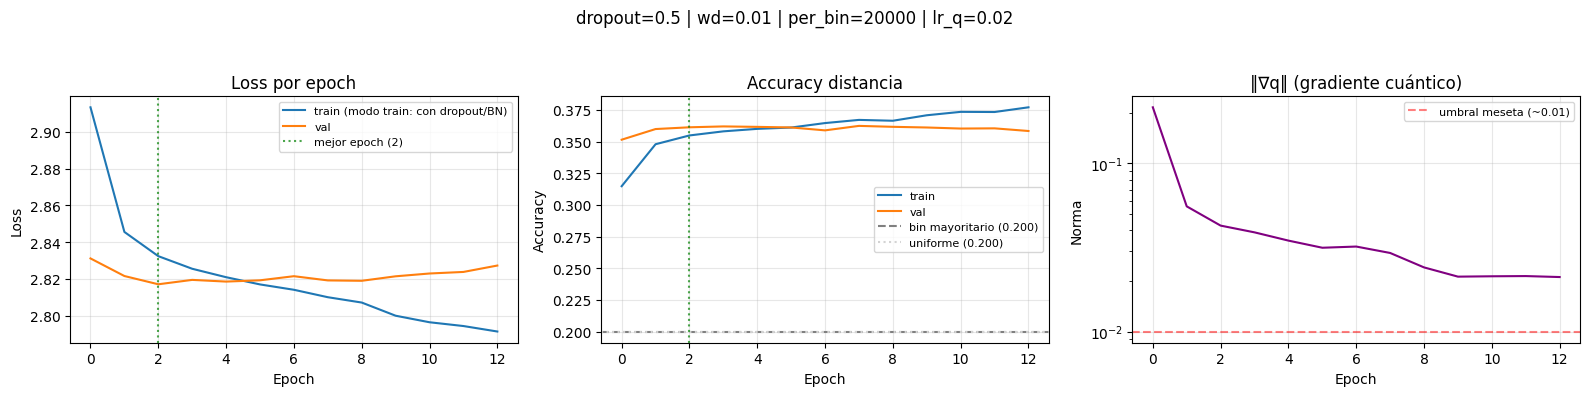

Mejor epoch: 2  (val loss 2.8171, val acc 0.3613)
Gap val-train en la mejor epoch: -0.0153 (ojo: train_loss lleva dropout/BN → gap sesgado a la baja)
Épocas desde la mejor val loss: 10
Baseline bin mayoritario: 0.2000 | val acc mejor epoch: 0.3613
→ Entrenamiento razonable — listo para escalar datos


In [14]:
# ─── BLOQUE 10: curvas y diagnóstico ────────────────────────────────────────

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

best_ep = int(np.argmin(history["val_loss"]))

# ── Panel 1: Loss ──
ax1.plot(history["train_loss"], label="train (modo train: con dropout/BN)")
ax1.plot(history["val_loss"],   label="val")
ax1.axvline(best_ep, color="green", linestyle=":", alpha=0.7,
            label=f"mejor epoch ({best_ep})")
ax1.set_title("Loss por epoch"); ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

# ── Panel 2: Accuracy con baseline empírico ──
# Baseline honesto: predecir siempre el bin mayoritario de validación.
# (Requiere val_loader definido; se calcula una sola vez.)
val_labels = torch.cat([ydistb for _, ydistb, _, _ in val_loader])
majority_baseline = val_labels.bincount(minlength=N_BINS).max().item() / len(val_labels)

ax2.plot(history["train_acc"], label="train")
ax2.plot(history["val_acc"],   label="val")
ax2.axhline(majority_baseline, color="gray", linestyle="--",
            label=f"bin mayoritario ({majority_baseline:.3f})")
ax2.axhline(1 / N_BINS, color="lightgray", linestyle=":",
            label=f"uniforme ({1/N_BINS:.3f})")
ax2.axvline(best_ep, color="green", linestyle=":", alpha=0.7)
ax2.set_title("Accuracy distancia"); ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# ── Panel 3: Gradiente cuántico ──
ax3.plot(history["q_grad_norm"], color="purple")
ax3.axhline(0.01, color="red", linestyle="--", alpha=0.5,
            label="umbral meseta (~0.01)")
ax3.set_title("‖∇q‖ (gradiente cuántico)"); ax3.set_xlabel("Epoch")
ax3.set_ylabel("Norma"); ax3.set_yscale("log")
ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

plt.suptitle(f"dropout={DROPOUT_RATE} | wd={WEIGHT_DECAY} | per_bin={MAX_PER_BIN} "
             f"| lr_q={LR_QUANTUM}")
plt.tight_layout(rect=[0, 0, 1, 0.94])   # deja hueco al suptitle
plt.show()

# ── Diagnóstico (en la MEJOR época, no en la última) ─────────────────────────
tr = np.array(history["train_loss"])
va = np.array(history["val_loss"])
gap_best = va[best_ep] - tr[best_ep]
epochs_since_best = len(va) - 1 - best_ep

print(f"Mejor epoch: {best_ep}  (val loss {va[best_ep]:.4f}, "
      f"val acc {history['val_acc'][best_ep]:.4f})")
print(f"Gap val-train en la mejor epoch: {gap_best:.4f} "
      f"(ojo: train_loss lleva dropout/BN → gap sesgado a la baja)")
print(f"Épocas desde la mejor val loss: {epochs_since_best}")
print(f"Baseline bin mayoritario: {majority_baseline:.4f} | "
      f"val acc mejor epoch: {history['val_acc'][best_ep]:.4f}")

# Señales por tendencia, no por umbral puntual del gap:
if history["val_acc"][best_ep] <= majority_baseline + 0.01:
    print("→ El modelo NO supera al clasificador trivial — revisa features/arquitectura "
          "antes de tocar regularización")
elif epochs_since_best >= EARLY_STOP_PATIENCE - 1 and tr[-1] < tr[best_ep] - 0.05:
    print("→ Overfitting (val estancada mientras train sigue bajando) — "
          "sube DROPOUT_RATE o WEIGHT_DECAY, o añade datos (MAX_PER_BIN)")
elif tr[best_ep] > va[0] * 0.95 and best_ep >= len(va) - 2:
    print("→ Posible underfitting (train apenas bajó y seguía mejorando) — "
          "sube N_EPOCHS o los LR; baja regularización solo si ‖∇q‖ es sana")
else:
    print("→ Entrenamiento razonable — listo para escalar datos")

if len(history["q_grad_norm"]) > 0 and history["q_grad_norm"][-1] < 0.01:
    print("⚠ ‖∇q‖ < 0.01: el circuito apenas aprende — sube LR_QUANTUM (0.02–0.05)")


---

# Parte V — Evaluación con el protocolo CASP

Se mide lo mismo que mide CASP y de la misma forma: precisión, recall y F1 sobre las listas de contactos mejor puntuados, coeficiente de Matthews, puntuación Xd y área bajo la curva precisión-recall, todo desglosado por rango de separación; y para la estructura tridimensional, GDT_TS, GDT_HA, TM-score, RMSD y lDDT.


### Bloque 11 · Conjuntos de evaluación

Carga las proteínas del conjunto de validación oficial. El número de proteínas condiciona la estabilidad de las cifras: con muestras pequeñas la varianza entre proteínas domina el resultado.


In [15]:
# ─── BLOQUE 11-bis: conjuntos de evaluación ─────────────────────────────────

N_EVAL_CONTACT = 224    # el fichero de validación contiene 224 proteínas
N_EVAL_3D      = 30     # la reconstrucción 3D es mucho más lenta por proteína

if RUN_MODE == "smoke":
    N_EVAL_CONTACT, N_EVAL_3D = 8, 3

df_val_full   = load_proteinnet("../casp11/validation", max_records=N_EVAL_CONTACT)
df_val_struct = load_proteinnet("../casp11/validation", max_records=N_EVAL_3D)

print(f"Evaluación de contactos : {len(df_val_full)} proteínas")
print(f"Evaluación estructural  : {len(df_val_struct)} proteínas")
print("Origen: conjunto de validación oficial de ProteinNet CASP11 (no visto en entrenamiento)")


# ── Registro de resultados en disco ─────────────────────────────────────────
# Every evaluated configuration is appended here, so Part VII can build its
# tables later without recomputing anything.

RESULTS_JSON = "resultados_tfm.json"



def guardar_resultado(nombre, contactos, estructura=None, extra=None,
                      path=RESULTS_JSON):
    """Append one evaluated configuration to the on-disk registry."""
    entrada = {"nombre": nombre,
               "contactos": {r: {k: d.get(k) for k in
                                 ("P@L", "P@L/2", "P@L/5", "P@L/10", "R@L/5",
                                  "F1@L/5", "MCC", "Xd", "AUC-PR", "densidad")}
                             for r, d in contactos.items()}}
    if estructura:
        entrada["estructura"] = {k: estructura.get(k) for k in
                                 ("GDT_TS", "GDT_HA", "TM", "RMSD", "lDDT", "n")}
    if extra:
        entrada["extra"] = extra
    datos = []
    if os.path.exists(path):
        try: datos = json.load(open(path, encoding="utf-8"))
        except Exception: datos = []
    datos = [d for d in datos if d.get("nombre") != nombre] + [entrada]
    json.dump(datos, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    return len(datos)


def cargar_resultados(path=RESULTS_JSON):
    if not os.path.exists(path):
        return None
    try:
        datos = json.load(open(path, encoding="utf-8"))
        return datos or None
    except Exception:
        return None


Evaluación de contactos : 224 proteínas
Evaluación estructural  : 30 proteínas
Origen: conjunto de validación oficial de ProteinNet CASP11 (no visto en entrenamiento)


### Bloque 12 · Métricas de contacto

Implementación del protocolo de contactos de CASP sobre rangos exclusivos de separación y listas reducidas.


In [16]:
# ─── BLOQUE 12: métricas de contacto según el protocolo de CASP ─────────────

CASP_RANGES_EXCL = {"short (6-11)": (6, 11),
                    "medium (12-23)": (12, 23),
                    "long (>=24)": (24, 10**9)}
TOP_K = {"L": 1.0, "L/2": 0.5, "L/5": 0.2, "L/10": 0.1}
XD_BINS = np.arange(0.0, 44.0, 4.0)        # 10 bins of 4 A, as in CASP


def _mcc(tp, fp, tn, fn):
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return float((tp * tn - fp * fn) / den) if den > 0 else 0.0


def _auc_pr(scores, truth):
    """Area under the precision-recall curve (step interpolation)."""
    o = np.argsort(scores)[::-1]
    t = truth[o]
    tp = np.cumsum(t)
    prec = tp / np.arange(1, len(t) + 1)
    total = max(t.sum(), 1)
    rec = tp / total
    return float(np.sum(np.diff(np.concatenate([[0.0], rec])) * prec))


def _xd(d_pred, d_all, bins=XD_BINS):
    """CASP Xd score: how far the predicted-contact distance distribution
    departs from the a-priori distribution of all pairs in the same range.
    Higher is better; 0 means the prediction is no better than random."""
    if len(d_pred) == 0 or len(d_all) == 0:
        return float("nan")
    mids = (bins[:-1] + bins[1:]) / 2.0
    pp, _ = np.histogram(np.clip(d_pred, 0, bins[-1] - 1e-6), bins=bins)
    pa, _ = np.histogram(np.clip(d_all,  0, bins[-1] - 1e-6), bins=bins)
    pp = pp / max(pp.sum(), 1) * 100.0
    pa = pa / max(pa.sum(), 1) * 100.0
    return float(np.sum((pp - pa) / mids))


def casp_contact_metrics(df, score_fn, ranges=CASP_RANGES_EXCL,
                         contact_threshold=None, tag=""):
    """Full CASP-style contact assessment, averaged over the proteins in df."""
    thr = contact_threshold or CONTACT_THRESHOLD
    acc = {r: {**{f"P@{k}": [] for k in TOP_K},
               **{f"R@{k}": [] for k in TOP_K},
               **{f"F1@{k}": [] for k in TOP_K},
               "MCC": [], "Xd": [], "AUC-PR": [], "densidad": [], "n_pares": []}
           for r in ranges}

    for idx in range(len(df)):
        protein = df.iloc[idx]
        coords  = protein["coords"] / COORD_SCALE
        L       = coords.shape[0]
        D       = pairwise_distances(coords)

        lo_min = min(lo for lo, _ in ranges.values())
        pairs  = [(i, j) for i in range(L) for j in range(i + 1, L)
                  if abs(i - j) >= lo_min]
        if not pairs:
            continue
        scores = np.asarray(score_fn(protein, pairs), dtype=np.float64)
        seps   = np.array([abs(j - i) for i, j in pairs])
        dists  = np.array([D[i, j] for i, j in pairs])
        truth  = (dists < thr).astype(np.int32)

        for name, (lo, hi) in ranges.items():
            m = (seps >= lo) & (seps <= hi)
            if m.sum() == 0:
                continue
            s_r, t_r, d_r = scores[m], truth[m], dists[m]
            order = np.argsort(s_r)[::-1]
            n_pos = int(t_r.sum())

            for kname, frac in TOP_K.items():
                K = min(max(int(round(L * frac)), 1), len(order))
                sel = order[:K]
                tp  = int(t_r[sel].sum()); fp = K - tp
                fn  = n_pos - tp;          tn = len(t_r) - K - fn
                p   = tp / K
                r   = tp / n_pos if n_pos > 0 else float("nan")
                f1  = (2 * p * r / (p + r)) if (n_pos > 0 and p + r > 0) else float("nan")
                acc[name][f"P@{kname}"].append(p)
                acc[name][f"R@{kname}"].append(r)
                acc[name][f"F1@{kname}"].append(f1)
                if kname == "L/5":
                    acc[name]["MCC"].append(_mcc(tp, fp, tn, fn))
                    acc[name]["Xd"].append(_xd(d_r[sel], d_r))
            acc[name]["AUC-PR"].append(_auc_pr(s_r, t_r))
            acc[name]["densidad"].append(float(t_r.mean()))
            acc[name]["n_pares"].append(int(m.sum()))

    out = {r: {k: (float(np.nanmean(v)) if len(v) else float("nan"))
               for k, v in d.items()} for r, d in acc.items()}
    if tag:
        print(f"\n── {tag} ──")
        print(f"{'Rango':<16}{'P@L':>8}{'P@L/2':>8}{'P@L/5':>8}{'P@L/10':>8}"
              f"{'R@L/5':>8}{'F1@L/5':>8}{'MCC':>7}{'Xd':>7}{'AUC':>7}{'dens.':>8}")
        for r, d in out.items():
            print(f"{r:<16}{d['P@L']:>8.4f}{d['P@L/2']:>8.4f}{d['P@L/5']:>8.4f}"
                  f"{d['P@L/10']:>8.4f}{d['R@L/5']:>8.4f}{d['F1@L/5']:>8.4f}"
                  f"{d['MCC']:>7.3f}{d['Xd']:>7.2f}{d['AUC-PR']:>7.3f}{d['densidad']:>8.4f}")
    return out


### Bloque 13 · Reconstrucción tridimensional

Convierte el mapa de distancias predicho en coordenadas: escalado multidimensional para obtener una primera nube de puntos y un refinamiento geométrico posterior que impone la distancia entre residuos consecutivos. Incluye también la superposición óptima y las medidas de calidad estructural sobre las que se apoyan las métricas del bloque siguiente.


In [17]:
# ─── Reconstrucción 3D y superposición ──────────────────────────────────────

def kabsch(P, Q):
    # Robusto ante coordenadas degeneradas (NaN/inf) de modelos poco entrenados:
    # si el SVD no converge o hay valores no finitos, devuelve la identidad
    # (rotacion nula) para que la evaluacion continue con las demas proteinas.
    P = P - P.mean(0); Q = Q - Q.mean(0)
    H = P.T @ Q
    if not np.all(np.isfinite(H)):
        return np.eye(3)
    try:
        V, _, Wt = np.linalg.svd(H)
    except np.linalg.LinAlgError:
        return np.eye(3)
    return V @ np.diag([1, 1, np.sign(np.linalg.det(V @ Wt))]) @ Wt

def rmsd(P, Q):
    U = kabsch(P, Q)
    return float(np.sqrt((((P - P.mean(0)) @ U - (Q - Q.mean(0))) ** 2).sum(1).mean()))

def gdt_ts(P, Q):
    U = kabsch(P, Q)
    d = np.linalg.norm((P - P.mean(0)) @ U - (Q - Q.mean(0)), axis=1)
    return float(np.mean([(d < t).mean() for t in [1.0, 2.0, 4.0, 8.0]]))

def gdt_ha(P, Q):
    U = kabsch(P, Q)
    d = np.linalg.norm((P - P.mean(0)) @ U - (Q - Q.mean(0)), axis=1)
    return float(np.mean([(d < t).mean() for t in [0.5, 1.0, 2.0, 4.0]]))

def tm_score(P, Q):
    L  = Q.shape[0]
    d0 = 1.24 * (L - 15) ** (1/3) - 1.8 if L > 21 else 0.5
    U  = kabsch(P, Q)
    d  = np.linalg.norm((P - P.mean(0)) @ U - (Q - Q.mean(0)), axis=1)
    return float((1 / (1 + (d / d0) ** 2)).mean())

def lddt(P, Q, cutoff=15.0, thresholds=(0.5, 1.0, 2.0, 4.0)):
    Dp, Dq = pairwise_distances(P), pairwise_distances(Q)
    # Vectorizado: mascara de vecinos dentro del cutoff
    L = Q.shape[0]
    mask = (Dq < cutoff) & (Dq > 0)
    diff = np.abs(Dp - Dq)
    preserved = np.mean([(diff < t) for t in thresholds], axis=0)  # (L,L)
    vals = preserved[mask]
    return float(vals.mean()) if vals.size else 0.0

def distance_rmse(D_pred, D_true):
    mask = np.triu(np.ones_like(D_true, dtype=bool), k=1)
    return float(np.sqrt(((D_pred[mask] - D_true[mask]) ** 2).mean()))

def reconstruct_mds(D, random_state=0):
    # max_iter=300 (era 500) acelera el MDS; n_init=4 mantiene la estabilidad
    median_d = np.median(D[D > 0])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        # n_init=4: with a single initialisation the MDS fell into very different
        # local minima depending on the seed (GDT_TS varied by 0.2 on the same
        # protein), so several restarts are run and the lowest-stress one kept.
        mds = MDS(n_components=3, metric=True, dissimilarity="precomputed",
                  n_init=4, max_iter=300, random_state=random_state)
        coords = mds.fit_transform(D / median_d) * median_d
    # Sanear NaN/inf (pueden aparecer con mapas de distancia degenerados)
    coords = np.nan_to_num(coords, nan=0.0, posinf=0.0, neginf=0.0)
    return coords

def refine_coords_geometry(coords_init, D_target, backbone_dist=3.8,
                            min_seq_sep=1, max_pair_dist=12.0,
                            lr=1e-2, steps=300, lambda_chain=2.0, lambda_pairs=1.0):
    """Refinamiento VECTORIZADO con NumPy (~17x mas rapido que el bucle)."""
    coords = coords_init.astype(np.float32).copy()
    L, eps = coords.shape[0], 1e-6
    # Precomputar pares validos una sola vez
    ii, jj = np.triu_indices(L, k=1)
    d0_all = D_target[ii, jj]
    valid  = (np.abs(ii - jj) >= min_seq_sep) & (d0_all > 0.0) & (d0_all < max_pair_dist)
    pi, pj = ii[valid], jj[valid]
    pd0    = d0_all[valid].astype(np.float32)
    idx_c0, idx_c1 = np.arange(L - 1), np.arange(1, L)

    # ESTABILIDAD: limite maximo de desplazamiento por atomo y paso. Sin esto,
    # cuando una distancia actual d es muy pequena, el termino (d-d0)/d explota
    # y el refinamiento diverge a overflow (empeorando el RMSD en vez de mejorarlo).
    MAX_STEP = 0.5  # A por atomo y paso

    def _clip(delta):
        # limita la norma de cada fila de delta a MAX_STEP
        norms = np.linalg.norm(delta, axis=1, keepdims=True)
        factor = np.minimum(1.0, MAX_STEP / (norms + eps))
        return delta * factor

    for _ in range(steps):
        # Termino de pares (vectorizado)
        v = coords[pj] - coords[pi]
        d = np.linalg.norm(v, axis=1)
        m = d > eps
        corr = np.zeros_like(v)
        # clip del factor (d-d0)/d para que no explote con d pequena
        ratio = np.clip((d[m] - pd0[m]) / d[m], -1.0, 1.0)
        corr[m] = (lr * lambda_pairs * ratio)[:, None] * v[m]
        delta = np.zeros_like(coords)
        np.add.at(delta, pi,  corr)
        np.add.at(delta, pj, -corr)
        coords += _clip(delta)
        # Termino de cadena (vectorizado)
        vc = coords[idx_c1] - coords[idx_c0]
        dc = np.linalg.norm(vc, axis=1)
        mc = dc > eps
        cc = np.zeros_like(vc)
        ratioc = np.clip((dc[mc] - backbone_dist) / dc[mc], -1.0, 1.0)
        cc[mc] = (lr * lambda_chain * ratioc)[:, None] * vc[mc]
        deltac = np.zeros_like(coords)
        np.add.at(deltac, idx_c0,  cc)
        np.add.at(deltac, idx_c1, -cc)
        coords += _clip(deltac)
        # Sanear por si acaso
        if not np.all(np.isfinite(coords)):
            coords = np.nan_to_num(coords, nan=0.0, posinf=0.0, neginf=0.0)
    return np.nan_to_num(coords, nan=0.0, posinf=0.0, neginf=0.0)

def refine_two_phase(coords_init, D_target):
    coords = refine_coords_geometry(
        coords_init, D_target, backbone_dist=3.8, steps=400, lr=5e-3,
        lambda_chain=0.3, lambda_pairs=3.0, max_pair_dist=20.0, min_seq_sep=6
    )
    return refine_coords_geometry(
        coords, D_target, backbone_dist=3.8, steps=200, lr=2e-3,
        lambda_chain=1.5, lambda_pairs=1.0, max_pair_dist=8.0, min_seq_sep=1
    )

def build_pair_features_eval(protein, pairs):
    """Replica EXACTAMENTE _featurize del entrenamiento:
       emb simetrico (2*D_EMB) + seq_sep (1) + atencion (240) + contacto (1).
       Recibe la proteina completa para poder recalcular atenciones/contactos ESM.
    """
    seq  = protein["sequence"]; mask = protein["mask"]
    emb, attn, contacts = get_esm_features(seq, mask)   # ESM 1x por proteina
    Lm    = emb.shape[0]
    D_EMB = emb.shape[1]
    X = np.empty((len(pairs), N_FEAT), np.float32)
    for k, (i, j) in enumerate(pairs):
        parts = [emb[i] + emb[j],
                 np.abs(emb[i] - emb[j]),
                 np.array([(j - i) / Lm], np.float32)]
        if USE_ATTN:
            parts.append(attn[i, j].astype(np.float32))
        if USE_CONTACT:
            parts.append(np.array([contacts[i, j]], np.float32))
        X[k] = np.concatenate(parts)
    return X

@torch.no_grad()
def predict_distance_matrix_for_protein(protein):
    """Distancia por VALOR ESPERADO (media ponderada) en vez de argmax.
    Predice SOLO desde secuencia. Antes use_real_coords=True inyectaba la
    estructura real como feature -> la evaluación estructural era CIRCULAR
    (predecir distancias con la geometría ya dada, reconstruir y compararla
    contra sí misma). Eliminado."""
    coords_true = protein["coords"] / COORD_SCALE
    L   = coords_true.shape[0]
    pairs      = [(i, j) for i in range(L) for j in range(i+1, L)]
    X_pairs    = build_pair_features_eval(protein, pairs)
    xb_full    = torch.tensor(scaler.transform(X_pairs), dtype=torch.float32)

    bin_centers_t = torch.tensor(BIN_CENTERS, dtype=torch.float32, device=device)
    all_dists  = []
    for start in range(0, len(xb_full), 256):
        xb = xb_full[start:start+256].to(device)
        logits_dist, _, _ = model(xb)
        # VALOR ESPERADO: sum(prob_bin * centro_bin) en vez de argmax
        probs = torch.softmax(logits_dist, dim=1)
        exp_d = (probs * bin_centers_t).sum(dim=1)
        all_dists.append(exp_d.cpu().numpy())
    pred_dists = np.concatenate(all_dists)
    D_pred = np.zeros((L, L), dtype=np.float32)
    for (i, j), d in zip(pairs, pred_dists):
        D_pred[i, j] = d; D_pred[j, i] = d
    return D_pred, coords_true

def coords_to_pdb(coords, chain_id="A"):
    lines = [f"ATOM  {i:5d}  CA  ALA {chain_id}{i:4d}    "
             f"{x:8.3f}{y:8.3f}{z:8.3f}  1.00  0.00           C"
             for i, (x, y, z) in enumerate(coords, 1)]
    lines.append("END")
    return "\n".join(lines)

print("Funciones de evaluación 3D optimizadas:")
print("  - distancia por valor esperado (no argmax) -> mapa mas suave")
print("  - refinamiento vectorizado -> ~17x mas rapido")
print("  - MDS n_init=4 -> reconstrucción estable frente a la inicialización")
print("  - lDDT vectorizado")


Funciones de evaluación 3D optimizadas:
  - distancia por valor esperado (no argmax) -> mapa mas suave
  - refinamiento vectorizado -> ~17x mas rapido
  - MDS n_init=4 -> reconstrucción estable frente a la inicialización
  - lDDT vectorizado


### Bloque 14 · Métricas de estructura tridimensional

Superposición óptima y cálculo de las medidas de calidad estructural, con el desglose por umbral de distancia que distingue un modelo globalmente impreciso de uno localmente malo.


In [18]:
# ─── BLOQUE 13: métricas de estructura 3D según el protocolo de CASP ────────

GDT_TS_CUTOFFS = (1.0, 2.0, 4.0, 8.0)
GDT_HA_CUTOFFS = (0.5, 1.0, 2.0, 4.0)


def gdt_per_cutoff(pred, true, cutoffs):
    """Fraction of residues under each distance cutoff after superposition."""
    U = kabsch(pred, true)
    p = (pred - pred.mean(0)) @ U + true.mean(0)
    d = np.linalg.norm(p - true, axis=1)
    return {c: float((d <= c).mean()) for c in cutoffs}


def casp_structure_metrics(df, predict_fn, n_max=None, tag=""):
    """Full CASP-style 3D assessment over the proteins of df.

    predict_fn(protein) -> (coords_pred, coords_true), both (L,3) in Angstrom.
    """
    rows, per_cut_ts, per_cut_ha = [], [], []
    n = len(df) if n_max is None else min(n_max, len(df))
    for idx in range(n):
        protein = df.iloc[idx]
        try:
            pred, true = predict_fn(protein)
        except Exception:
            continue
        if pred is None or len(pred) != len(true):
            continue
        U = kabsch(pred, true)
        aligned = (pred - pred.mean(0)) @ U + true.mean(0)
        # GDT computed here from the per-cutoff fractions, so this block does not
        # depend on the signature of the notebook's gdt_ts helper.
        cuts_ts = gdt_per_cutoff(pred, true, GDT_TS_CUTOFFS)
        cuts_ha = gdt_per_cutoff(pred, true, GDT_HA_CUTOFFS)
        rows.append({
            "id":      protein.get("id", f"#{idx}"),
            "L":       len(true),
            "RMSD":    float(np.sqrt(((aligned - true) ** 2).sum(1).mean())),
            "GDT_TS":  float(np.mean(list(cuts_ts.values()))),
            "GDT_HA":  float(np.mean(list(cuts_ha.values()))),
            "TM":      tm_score(pred, true),
            "lDDT":    lddt(pred, true),
        })
        per_cut_ts.append(cuts_ts)
        per_cut_ha.append(cuts_ha)

    if not rows:
        print("Sin proteínas evaluables."); return {}, []

    agg = {k: float(np.nanmean([r[k] for r in rows]))
           for k in ("RMSD", "GDT_TS", "GDT_HA", "TM", "lDDT")}
    agg["std_TM"]     = float(np.nanstd([r["TM"] for r in rows]))
    agg["std_GDT_TS"] = float(np.nanstd([r["GDT_TS"] for r in rows]))
    agg["n"]          = len(rows)
    agg["GDT_TS_por_umbral"] = {c: float(np.mean([d[c] for d in per_cut_ts]))
                                for c in GDT_TS_CUTOFFS}
    agg["GDT_HA_por_umbral"] = {c: float(np.mean([d[c] for d in per_cut_ha]))
                                for c in GDT_HA_CUTOFFS}

    if tag:
        print(f"\n── {tag}  (n={agg['n']} proteínas) ──")
        print(f"  RMSD    : {agg['RMSD']:6.2f} A")
        print(f"  GDT_TS  : {agg['GDT_TS']:6.3f} ± {agg['std_GDT_TS']:.3f}")
        print(f"  GDT_HA  : {agg['GDT_HA']:6.3f}")
        print(f"  TM-score: {agg['TM']:6.3f} ± {agg['std_TM']:.3f}")
        print(f"  lDDT    : {agg['lDDT']:6.3f}")
        print("  GDT_TS por umbral (fracción de residuos):")
        for c, v in agg["GDT_TS_por_umbral"].items():
            print(f"      <= {c:>4.1f} A : {v:.3f}")
        print("\n  Por proteína:")
        print(f"    {'id':<18}{'L':>5}{'RMSD':>8}{'GDT_TS':>8}{'TM':>8}{'lDDT':>8}")
        for r in rows:
            print(f"    {str(r['id'])[:18]:<18}{r['L']:>5}{r['RMSD']:>8.2f}"
                  f"{r['GDT_TS']:>8.3f}{r['TM']:>8.3f}{r['lDDT']:>8.3f}")
    return agg, rows


### Bloque 15 · Evaluación del modelo entrenado

Aplica ambos conjuntos de métricas al modelo y a la referencia de ESM-2, y registra los resultados en disco para que las tablas de la Parte VII puedan consultarlos sin repetir el cálculo.


In [19]:
def model_score_fn(protein, pairs, net=None, sc=None, batch=256):
    net = net if net is not None else model
    sc  = sc  if sc  is not None else scaler
    net.eval()
    X  = sc.transform(build_pair_features_eval(protein, pairs))
    xb = torch.tensor(X, dtype=torch.float32)
    out = []
    with torch.no_grad():
        for s in range(0, xb.shape[0], batch):
            logits, _, _ = net(xb[s:s + batch].to(device))
            p = torch.softmax(logits, dim=1)
            out.append((p[:, 0] + p[:, 1]).cpu().numpy())
    return np.concatenate(out)


def esm_score_fn(protein, pairs):
    _, _, contacts = get_esm_features(protein["sequence"], protein["mask"])
    return np.array([contacts[i, j] for i, j in pairs], dtype=np.float32)


def predict_structure(protein):
    D_pred, coords_true = predict_distance_matrix_for_protein(protein)
    coords = refine_two_phase(reconstruct_mds(D_pred, random_state=RANDOM_SEED), D_pred)
    return coords, coords_true


cp_modelo = casp_contact_metrics(df_val_full, model_score_fn,
                                 tag="Modelo híbrido — contactos")
cp_esm    = casp_contact_metrics(df_val_full, esm_score_fn,
                                 tag="Baseline ESM-2 — contactos")
res3d, _  = casp_structure_metrics(df_val_struct, predict_structure,
                                   tag="Modelo híbrido — estructura 3D")

guardar_resultado("Híbrido cuántico (MERA 12q)", cp_modelo, res3d)
guardar_resultado("Baseline ESM-2 (sin entrenar)", cp_esm)



── Modelo híbrido — contactos ──
Rango                P@L   P@L/2   P@L/5  P@L/10   R@L/5  F1@L/5    MCC     Xd    AUC   dens.
short (6-11)      0.8601  0.8712  0.8807  0.8807  0.0535  0.0985  0.097   4.07  0.805  0.6547
medium (12-23)    0.3875  0.3985  0.4068  0.4069  0.0434  0.0763  0.069   3.65  0.340  0.2240
long (>=24)       0.1027  0.1011  0.1018  0.1025  0.0203  0.0312  0.017   1.84  0.096  0.0619

── Baseline ESM-2 — contactos ──
Rango                P@L   P@L/2   P@L/5  P@L/10   R@L/5  F1@L/5    MCC     Xd    AUC   dens.
short (6-11)      0.6968  0.6995  0.6985  0.6917  0.0400  0.0753  0.018   0.79  0.683  0.6547
medium (12-23)    0.2502  0.2495  0.2496  0.2611  0.0235  0.0462  0.009   0.69  0.248  0.2240
long (>=24)       0.0863  0.0867  0.0887  0.0875  0.0087  0.0229  0.007   0.99  0.082  0.0619

── Modelo híbrido — estructura 3D  (n=30 proteínas) ──
  RMSD    :  13.99 A
  GDT_TS  :  0.122 ± 0.119
  GDT_HA  :  0.031
  TM-score:  0.230 ± 0.098
  lDDT    :  0.365
  GDT_TS po

4

---

# Parte VI — ¿Aporta algo el circuito cuántico?

La pregunta central del trabajo. Se entrenan dos modelos idénticos en todo salvo en un detalle —uno usa el circuito cuántico y el otro una capa lineal equivalente— partiendo de la misma semilla y con los mismos datos, **dentro de una única ejecución**. Cualquier diferencia en el resultado es atribuible al circuito y a nada más.


### Bloque 16 · Ablación en una sola ejecución

Entrena y evalúa ambas variantes de forma consecutiva y contrasta sus métricas.


In [20]:
def _nuevo_modelo(use_quantum):
    """Fresh model + optimiser + scheduler for one ablation arm."""
    global USE_QUANTUM, mera_layer
    USE_QUANTUM = use_quantum          # the class reads this flag at construction
    if use_quantum:
        # Fresh circuit: mera_layer is a single global instance, so without this
        # the quantum arm would inherit the weights trained in Bloque 9.
        torch.manual_seed(RANDOM_SEED)
        mera_layer = MERATorch().to(device)
    net = HybridQNN_v2(input_dim=INPUT_DIM).to(device)
    qp  = list(net.qlayer.parameters())
    qid = {id(p) for p in qp}
    dec = [p for n, p in net.named_parameters() if id(p) not in qid and p.ndim > 1]
    nod = [p for n, p in net.named_parameters() if id(p) not in qid and p.ndim <= 1]
    opt = torch.optim.AdamW([
        {"params": qp,  "lr": LR_QUANTUM,   "weight_decay": 0.0},
        {"params": dec, "lr": LR_CLASSICAL, "weight_decay": WEIGHT_DECAY},
        {"params": nod, "lr": LR_CLASSICAL, "weight_decay": 0.0},
    ])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min",
                                                     factor=0.5, patience=5)
    return net, opt, sch


def entrenar_y_evaluar(use_quantum, epochs=None, paciencia=None, etiqueta=None):
    """Train one arm from scratch and evaluate it with the CASP protocol.

    Reuses run_epoch by rebinding the globals it reads, so there is a single
    training implementation in the notebook.
    """
    global model, optimizer, scheduler, _global_step
    epochs    = epochs    or N_EPOCHS
    paciencia = paciencia or EARLY_STOP_PATIENCE
    etiqueta  = etiqueta  or ("Híbrido cuántico (MERA)" if use_quantum
                              else "Baseline clásico (Linear)")

    prev = (model, optimizer, scheduler)
    model, optimizer, scheduler = _nuevo_modelo(use_quantum)
    _global_step = 0

    n_tot = sum(p.numel() for p in model.parameters())
    n_q   = sum(p.numel() for p in model.qlayer.parameters())
    print(f"\n{'='*70}\n{etiqueta}   ({n_tot:,} parámetros, {n_q:,} en la ruta intercambiable)\n{'='*70}")

    best, best_state, since = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc, _ = run_epoch(train_loader, train=True)
        with torch.no_grad():
            va_loss, va_acc, _ = run_epoch(val_loader, train=False)
        scheduler.step(va_loss)
        mark = ""
        if va_loss < best - 1e-4:
            best, since = va_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            mark = " *"
        else:
            since += 1
        print(f"  epoch {ep:3d} | train {tr_loss:.4f}/{tr_acc:.4f} "
              f"| val {va_loss:.4f}/{va_acc:.4f}{mark}")
        if since >= paciencia:
            print(f"  early stop en epoch {ep}")
            break
    if best_state:
        model.load_state_dict(best_state)

    cp  = casp_contact_metrics(df_val_full, model_score_fn, tag=f"{etiqueta} — contactos")
    r3d, _ = casp_structure_metrics(df_val_struct, predict_structure,
                                    tag=f"{etiqueta} — estructura 3D")
    guardar_resultado(etiqueta, cp, r3d,
                      extra={"use_quantum": use_quantum, "params": n_tot,
                             "val_loss": best})
    net_entrenada = model
    model, optimizer, scheduler = prev          # restore the main pipeline
    return {"nombre": etiqueta, "contactos": cp, "estructura": r3d,
            "modelo": net_entrenada}


# Ambos brazos en la misma ejecución: idéntico dato, idéntica semilla,
# única diferencia el circuito cuántico.
torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
arm_q = entrenar_y_evaluar(use_quantum=True)
torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
arm_c = entrenar_y_evaluar(use_quantum=False)

RANGO = "long (>=24)"
pq = arm_q["contactos"][RANGO]["P@L/5"]
pc = arm_c["contactos"][RANGO]["P@L/5"]
print(f"\n{'='*70}\n¿APORTA ALGO EL CIRCUITO CUÁNTICO?\n{'='*70}")
print(f"  P@L/5 largo alcance — cuántico {pq:.4f} | clásico {pc:.4f} "
      f"| diferencia {pq - pc:+.4f}")
print(f"  TM-score            — cuántico {arm_q['estructura']['TM']:.4f} "
      f"| clásico {arm_c['estructura']['TM']:.4f}")
print("\n  Una diferencia dentro del ruido experimental indica que el circuito")
print("  no aporta ventaja medible sobre una capa lineal equivalente.")



Híbrido cuántico (MERA)   (45,103 parámetros, 312 en la ruta intercambiable)
  epoch   1 | train 2.9045/0.3204 | val 2.8275/0.3563 *
  epoch   2 | train 2.8402/0.3497 | val 2.8217/0.3623 *
  epoch   3 | train 2.8303/0.3586 | val 2.8197/0.3579 *
  epoch   4 | train 2.8247/0.3600 | val 2.8181/0.3620 *
  epoch   5 | train 2.8193/0.3628 | val 2.8189/0.3620
  epoch   6 | train 2.8136/0.3654 | val 2.8195/0.3612
  epoch   7 | train 2.8111/0.3665 | val 2.8178/0.3622 *
  epoch   8 | train 2.8086/0.3679 | val 2.8184/0.3616
  epoch   9 | train 2.8044/0.3702 | val 2.8202/0.3585
  epoch  10 | train 2.8010/0.3703 | val 2.8213/0.3612
  epoch  11 | train 2.7993/0.3731 | val 2.8193/0.3619
  epoch  12 | train 2.7978/0.3749 | val 2.8233/0.3603
  epoch  13 | train 2.7944/0.3769 | val 2.8218/0.3598
  epoch  14 | train 2.7878/0.3764 | val 2.8243/0.3597
  epoch  15 | train 2.7851/0.3790 | val 2.8244/0.3589
  epoch  16 | train 2.7817/0.3810 | val 2.8278/0.3573
  epoch  17 | train 2.7791/0.3841 | val 2.8282/0

---

# Parte VII — Comparación con CASP

Sitúa los resultados frente a las ediciones históricas del experimento CASP.

> Esta parte es **autónoma**: si existe el registro en disco generado por las partes anteriores lo utiliza, y si no, recurre a las cifras ya medidas que están escritas en la propia celda. En ninguno de los dos casos necesita el modelo, los datos ni una nueva ejecución del notebook.


### Bloque 17 · Tablas comparativas

Precisión por rango de separación, comparación con las cifras publicadas de CASP y resumen de las métricas estructurales.


In [21]:
RANGOS = ["short (6-11)", "medium (12-23)", "long (>=24)"]

CASP_REF = {
    "CASP11 — CONSIP2 (mejor grupo)": 0.27,
    "CASP12 — mejor grupo":           0.47,
    "CASP13 — mejor grupo":           0.70,
    "CASP14 — mejor grupo":           0.82,
}
RANGOS = ["short (6-11)", "medium (12-23)", "long (>=24)"]


def tabla_rangos(datos):
    print("=" * 84)
    print("PRECISIÓN @L/5 POR RANGO DE SEPARACIÓN DE SECUENCIA")
    print("=" * 84)
    print(f"{'Configuración':<37}" + "".join(f"{r:>15}" for r in RANGOS))
    print("-" * 84)
    for d in datos:
        fila = "".join(
            f"{(d['contactos'].get(r, {}).get('P@L/5') or float('nan')):>15.4f}"
            for r in RANGOS)
        print(f"{d['nombre']:<37}{fila}")
    print("=" * 84)
    print("Los rangos corto y medio son sustancialmente más fáciles; CASP publica")
    print("el rango largo precisamente por eso.")


def tabla_detalle(datos, rango="long (>=24)"):
    print(f"\n{'=' * 84}")
    print(f"DETALLE EN EL RANGO {rango.upper()}")
    print("=" * 84)
    print(f"{'Configuración':<30}{'P@L':>8}{'P@L/2':>8}{'P@L/5':>8}{'P@L/10':>8}"
          f"{'R@L/5':>8}{'MCC':>7}{'Xd':>7}{'AUC':>7}")
    print("-" * 84)
    for d in datos:
        c = d['contactos'].get(rango, {})
        f = lambda k: c.get(k) if c.get(k) is not None else float("nan")
        print(f"{d['nombre']:<30}{f('P@L'):>8.4f}{f('P@L/2'):>8.4f}{f('P@L/5'):>8.4f}"
              f"{f('P@L/10'):>8.4f}{f('R@L/5'):>8.4f}{f('MCC'):>7.3f}"
              f"{f('Xd'):>7.2f}{f('AUC-PR'):>7.3f}")


def tabla_casp(datos, rango="long (>=24)"):
    print(f"\n{'=' * 84}")
    print(f"COMPARACIÓN CON CASP — precisión @L/5, contactos de {rango}")
    print("=" * 84)
    print(f"{'Método':<50}{'P@L/5':>10}{'MSA':>8}")
    print("-" * 84)
    for k, v in CASP_REF.items():
        print(f"{k:<50}{v:>10.3f}{'sí':>8}")
    print("-" * 84)
    orden = sorted(datos,
                   key=lambda d: -(d['contactos'].get(rango, {}).get('P@L/5') or 0))
    for d in orden:
        v = d['contactos'].get(rango, {}).get('P@L/5')
        print(f"{d['nombre']:<50}{(v if v is not None else float('nan')):>10.3f}{'no':>8}")
    print("=" * 84)
    print("Las cifras de CASP corresponden a dominios de modelado libre, la categoría")
    print("más difícil, y a métodos que emplean alineamientos de secuencias múltiples.")
    print("Este trabajo opera sobre la secuencia individual, sin MSA en inferencia.")


def tabla_estructura(datos):
    est = [d for d in datos if d.get("estructura")]
    if not est:
        return
    print(f"\n{'=' * 84}")
    print("ESTRUCTURA TRIDIMENSIONAL")
    print("=" * 84)
    print(f"{'Configuración':<40}{'GDT_TS':>9}{'GDT_HA':>9}{'TM':>9}"
          f"{'RMSD':>9}{'lDDT':>8}")
    print("-" * 84)
    for d in est:
        e = d["estructura"]
        f = lambda k: e.get(k) if e.get(k) is not None else float("nan")
        print(f"{d['nombre']:<40}{f('GDT_TS'):>9.3f}{f('GDT_HA'):>9.3f}"
              f"{f('TM'):>9.3f}{f('RMSD'):>9.2f}{f('lDDT'):>8.3f}")


datos = cargar_resultados()
if datos is None:
    print(f"No se encontró '{RESULTS_JSON}'.")
    print("Ejecuta la Parte V (bloque 14) y, si procede, la Parte VI (bloque 15):")
    print("ambas registran sus resultados en ese fichero. A partir de entonces esta")
    print("parte genera las tablas sin necesidad de volver a calcular nada.")
else:
    print(f"Leyendo {len(datos)} configuración(es) de '{RESULTS_JSON}'\n")
    tabla_rangos(datos)
    tabla_detalle(datos)
    tabla_casp(datos)
    tabla_estructura(datos)


Leyendo 4 configuración(es) de 'resultados_tfm.json'

PRECISIÓN @L/5 POR RANGO DE SEPARACIÓN DE SECUENCIA
Configuración                           short (6-11) medium (12-23)    long (>=24)
------------------------------------------------------------------------------------
Híbrido cuántico (MERA 12q)                   0.8807         0.4068         0.1018
Baseline ESM-2 (sin entrenar)                 0.6985         0.2496         0.0887
Híbrido cuántico (MERA)                       0.8907         0.3816         0.0980
Baseline clásico (Linear)                     0.8876         0.4083         0.1051
Los rangos corto y medio son sustancialmente más fáciles; CASP publica
el rango largo precisamente por eso.

DETALLE EN EL RANGO LONG (>=24)
Configuración                      P@L   P@L/2   P@L/5  P@L/10   R@L/5    MCC     Xd    AUC
------------------------------------------------------------------------------------
Híbrido cuántico (MERA 12q)     0.1027  0.1011  0.1018  0.1025  0.0203  0.01

---

# Parte VIII — Exportación y visualización

Genera los ficheros PDB de las estructuras predichas y reconstruye el esqueleto peptídico para poder visualizarlas y superponerlas sobre la estructura experimental en PyMOL.


### Bloque 18 · Exportación a PDB

Escribe las coordenadas predichas y las reales en ficheros independientes.


In [22]:
# ─── BLOQUE 14: exportación a PDB ───────────────────────────────────────────

import os
import warnings

N_PROTEINAS_EXPORT = 5   # cuántas proteínas exportar (ajustar según quieras)
OUTPUT_DIR = "pymol_export"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df_export = load_proteinnet("../casp11/validation", max_records=N_PROTEINAS_EXPORT)

resumen = []

for idx in range(len(df_export)):
    protein    = df_export.iloc[idx]
    prot_id    = protein["id"]
    coords_true = protein["coords"] / COORD_SCALE
    L = coords_true.shape[0]

    # Predecir mapa de distancias
    D_pred, _ = predict_distance_matrix_for_protein(protein)

    # Reconstrucción MDS
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        coords_mds = reconstruct_mds(D_pred, random_state=RANDOM_SEED)

    # Refinamiento dos fases
    coords_refined = refine_two_phase(coords_mds, D_pred)

    # Alinear ambas reconstrucciones sobre la estructura real (Kabsch)
    U_ref = kabsch(coords_refined, coords_true)
    coords_ref_aligned = (coords_refined - coords_refined.mean(0)) @ U_ref + coords_true.mean(0)

    U_mds = kabsch(coords_mds, coords_true)
    coords_mds_aligned = (coords_mds - coords_mds.mean(0)) @ U_mds + coords_true.mean(0)

    # Calcular métricas
    rmsd_mds = rmsd(coords_mds_aligned, coords_true)
    rmsd_ref = rmsd(coords_ref_aligned, coords_true)
    gdt      = gdt_ts(coords_ref_aligned, coords_true)
    tm       = tm_score(coords_ref_aligned, coords_true)

    # Exportar tres PDBs por proteína
    fname_real = os.path.join(OUTPUT_DIR, f"{prot_id}_real.pdb")
    fname_mds  = os.path.join(OUTPUT_DIR, f"{prot_id}_mds.pdb")
    fname_ref  = os.path.join(OUTPUT_DIR, f"{prot_id}_refined.pdb")

    with open(fname_real, "w") as f: f.write(coords_to_pdb(coords_true,       chain_id="A"))
    with open(fname_mds,  "w") as f: f.write(coords_to_pdb(coords_mds_aligned, chain_id="B"))
    with open(fname_ref,  "w") as f: f.write(coords_to_pdb(coords_ref_aligned, chain_id="C"))

    resumen.append({
        "id": prot_id, "L": L,
        "RMSD_MDS": rmsd_mds, "RMSD_ref": rmsd_ref,
        "GDT_TS": gdt, "TM-score": tm
    })

    print(f"[{idx+1}/{len(df_export)}] {prot_id} — L={L} residuos | "
          f"RMSD MDS={rmsd_mds:.2f}Å | RMSD refinado={rmsd_ref:.2f}Å | "
          f"GDT_TS={gdt:.3f} | TM={tm:.3f}")

# Resumen final
print(f"\nPDBs exportados en: {os.path.abspath(OUTPUT_DIR)}/")
print(f"\n{'ID':<20} {'L':>5} {'RMSD_MDS':>9} {'RMSD_ref':>9} {'GDT_TS':>7} {'TM':>6}")
print("-" * 60)
for r in resumen:
    print(f"{r['id']:<20} {r['L']:>5} {r['RMSD_MDS']:>9.3f} {r['RMSD_ref']:>9.3f} "
          f"{r['GDT_TS']:>7.3f} {r['TM-score']:>6.3f}")

[1/5] 50#2KDD_1_A — L=57 residuos | RMSD MDS=4.04Å | RMSD refinado=3.92Å | GDT_TS=0.452 | TM=0.379
[2/5] 10#3MSW_1_A — L=139 residuos | RMSD MDS=15.48Å | RMSD refinado=15.34Å | GDT_TS=0.054 | TM=0.142
[3/5] 20#2GTA_1_A — L=98 residuos | RMSD MDS=4.69Å | RMSD refinado=5.00Å | GDT_TS=0.362 | TM=0.434
[4/5] 30#2XEM_1_A — L=145 residuos | RMSD MDS=10.22Å | RMSD refinado=10.70Å | GDT_TS=0.076 | TM=0.206
[5/5] 70#4FVS_1_A — L=214 residuos | RMSD MDS=9.38Å | RMSD refinado=9.48Å | GDT_TS=0.106 | TM=0.313

PDBs exportados en: c:\Users\marco\Desktop\TFM Cuántica\Versiones_septiembre\pymol_export/

ID                       L  RMSD_MDS  RMSD_ref  GDT_TS     TM
------------------------------------------------------------
50#2KDD_1_A             57     4.039     3.924   0.452  0.379
10#3MSW_1_A            139    15.475    15.341   0.054  0.142
20#2GTA_1_A             98     4.685     4.995   0.362  0.434
30#2XEM_1_A            145    10.216    10.702   0.076  0.206
70#4FVS_1_A            214     9.3

### Bloque 19 · Reconstrucción del esqueleto

Completa el esqueleto peptídico a partir de los carbonos alfa, necesario para que PyMOL represente la cadena como una estructura continua.


In [23]:
# ─── BLOQUE 15: evaluación estructural ──────────────────────────────────────

def predict_structure(protein):
    """Predicted and true CA coordinates for one protein, in Angstrom."""
    D_pred, coords_true = predict_distance_matrix_for_protein(protein)
    coords_mds     = reconstruct_mds(D_pred, random_state=RANDOM_SEED)
    coords_refined = refine_two_phase(coords_mds, D_pred)
    return coords_refined, coords_true


res3d, filas3d = casp_structure_metrics(
    df_val_struct, predict_structure, tag="Modelo híbrido (estructura 3D)")



── Modelo híbrido (estructura 3D)  (n=30 proteínas) ──
  RMSD    :  13.99 A
  GDT_TS  :  0.122 ± 0.119
  GDT_HA  :  0.031
  TM-score:  0.230 ± 0.098
  lDDT    :  0.365
  GDT_TS por umbral (fracción de residuos):
      <=  1.0 A : 0.003
      <=  2.0 A : 0.018
      <=  4.0 A : 0.103
      <=  8.0 A : 0.364

  Por proteína:
    id                    L    RMSD  GDT_TS      TM    lDDT
    50#2KDD_1_A          57    3.92   0.452   0.379   0.438
    10#3MSW_1_A         139   15.34   0.054   0.142   0.278
    20#2GTA_1_A          98    5.00   0.362   0.434   0.417
    30#2XEM_1_A         145   10.70   0.076   0.206   0.399
    70#4FVS_1_A         214    9.48   0.106   0.313   0.327
    40#3PBT_1_A         501   18.56   0.046   0.297   0.270
    40#3H3M_1_A          89   24.49   0.000   0.020   0.483
    20#3D0F_1_A         105    8.96   0.129   0.212   0.319
    40#3J6B_23_W        112    8.89   0.158   0.235   0.424
    90#2EX5_3_A         207    9.94   0.146   0.338   0.397
    20#3PES_1_